# Instructor Effectiveness Modeling

### Data Science / AI Content Specialist Internship Assignment

## 1. Problem Understanding

The objective of this assignment is to estimate instructor effectiveness using batch-level learner outcomes, engagement metrics, and learner feedback.

Each row in the dataset represents one course batch, while an instructor may teach multiple batches and courses. Therefore, the analysis needs to aggregate batch-level information to the instructor level before assigning an effectiveness tier.

The analysis will follow these major steps:

1. Explore and understand the dataset through Exploratory Data Analysis (EDA).
2. Define an Instructor Effectiveness Score using learner outcomes, engagement, and feedback metrics.
3. Aggregate batch-level data to the instructor level.
4. Convert the effectiveness score into effectiveness tiers such as Low, Medium, and High.
5. Build a classical machine learning classification model to predict the effectiveness tier.
6. Evaluate the model using appropriate classification metrics.
7. Interpret the important features and discuss limitations, confounding factors, and potential real-world use cases.

The objective is not only to obtain a high prediction accuracy, but also to develop a transparent and well-justified methodology.

In [40]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

## 2. Data Loading and Initial Inspection

The dataset is provided as an Excel file. It contains batch-level information about instructors, courses, learner outcomes, learner engagement, and feedback.

The first step is to load the dataset and perform basic structural checks before beginning the exploratory analysis.

In [41]:
file_path = "instructor_effectiveness_dataset_2000_rows.xlsx"

df = pd.read_excel(file_path, engine="openpyxl")
df.head()

,batch_id,instructor_id,course_id,completion_rate,avg_score_improvement,avg_quiz_score,dropout_rate,avg_watch_time,assignment_submission_rate,forum_activity_rate,avg_feedback_score,feedback_response_rate
0,B_1861,I_044,C_01,0.300000,14.225955,73.546528,0.647423,0.774572,0.790918,0.108414,3.766211,0.533193
1,B_0354,I_119,C_06,0.657220,22.871110,77.312331,0.425098,0.494936,0.998566,0.280550,5.000000,0.734087
2,B_1334,I_050,C_03,0.300000,16.087517,79.563687,0.700000,0.977901,0.807298,0.207013,3.517386,0.681433
3,B_0906,I_024,C_21,0.639507,24.260687,99.295316,0.334657,0.846515,0.544555,0.306395,4.207578,1.000000
4,B_1290,I_001,C_08,0.527302,31.081556,99.393425,0.521099,0.917450,0.865885,0.252289,4.426230,0.696710


In [42]:
print("Dataset Shape: ",df.shape)
print("\n Column names: ")
print(df.columns.tolist())

Dataset Shape:  (2000, 12)

 Column names: 
['batch_id', 'instructor_id', 'course_id', 'completion_rate', 'avg_score_improvement', 'avg_quiz_score', 'dropout_rate', 'avg_watch_time', 'assignment_submission_rate', 'forum_activity_rate', 'avg_feedback_score', 'feedback_response_rate']


In [43]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   batch_id                    2000 non-null   object 
 1   instructor_id               2000 non-null   object 
 2   course_id                   2000 non-null   object 
 3   completion_rate             2000 non-null   float64
 4   avg_score_improvement       2000 non-null   float64
 5   avg_quiz_score              2000 non-null   float64
 6   dropout_rate                2000 non-null   float64
 7   avg_watch_time              2000 non-null   float64
 8   assignment_submission_rate  2000 non-null   float64
 9   forum_activity_rate         2000 non-null   float64
 10  avg_feedback_score          2000 non-null   float64
 11  feedback_response_rate      2000 non-null   float64
dtypes: float64(9), object(3)
memory usage: 187.6+ KB


In [44]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
completion_rate,2000.0,0.602808,0.159667,0.300000,0.489260,0.603091,0.712797,0.980000
avg_score_improvement,2000.0,27.035844,5.716641,6.159240,23.124673,26.938629,30.885600,40.000000
avg_quiz_score,2000.0,77.956126,10.695618,40.386725,70.897590,78.020567,85.444286,100.000000
dropout_rate,2000.0,0.394883,0.162747,0.020000,0.280035,0.394820,0.511432,0.700000
avg_watch_time,2000.0,0.776515,0.145231,0.287440,0.675076,0.780330,0.894242,1.000000
assignment_submission_rate,2000.0,0.753188,0.148058,0.251111,0.652110,0.756380,0.856458,1.000000
forum_activity_rate,2000.0,0.250300,0.100640,0.000000,0.179845,0.249771,0.319204,0.641111
avg_feedback_score,2000.0,4.207134,0.419209,2.639915,3.918986,4.205989,4.503437,5.000000
feedback_response_rate,2000.0,0.736519,0.149412,0.259935,0.633293,0.737213,0.845876,1.000000


In [45]:
missing_values = df.isnull().sum()
missing_values

batch_id                      0
instructor_id                 0
course_id                     0
completion_rate               0
avg_score_improvement         0
avg_quiz_score                0
dropout_rate                  0
avg_watch_time                0
assignment_submission_rate    0
forum_activity_rate           0
avg_feedback_score            0
feedback_response_rate        0
dtype: int64

In [46]:
duplicate_count = df.duplicated().sum()
print("Number of duplicate rows: ",duplicate_count)

Number of duplicate rows:  0


In [47]:
print("Unique batch IDs: ",df["batch_id"].nunique())
print("Total rows: ",len(df))

Unique batch IDs:  2000
Total rows:  2000


In [48]:
instructor_batch_counts = df["instructor_id"].value_counts()
instructor_batch_counts.describe()

print("Number of unique instructors: ",df["instructor_id"].nunique())
print("Minimum batches per instructor:", instructor_batch_counts.min())
print("Maximum batches per instructor:", instructor_batch_counts.max())
print("Average batches per instructor:", instructor_batch_counts.mean())
print("Median batches per instructor:", instructor_batch_counts.median())

Number of unique instructors:  120
Minimum batches per instructor: 7
Maximum batches per instructor: 31
Average batches per instructor: 16.666666666666668
Median batches per instructor: 17.0


In [49]:
course_counts = df["course_id"].value_counts().sort_index()
course_counts

course_id
C_01    72
C_02    85
C_03    86
C_04    86
C_05    77
C_06    81
C_07    68
C_08    88
C_09    84
C_10    69
C_11    70
C_12    84
C_13    83
C_14    88
C_15    88
C_16    64
C_17    81
C_18    80
C_19    72
C_20    84
C_21    91
C_22    79
C_23    77
C_24    80
C_25    83
Name: count, dtype: int64

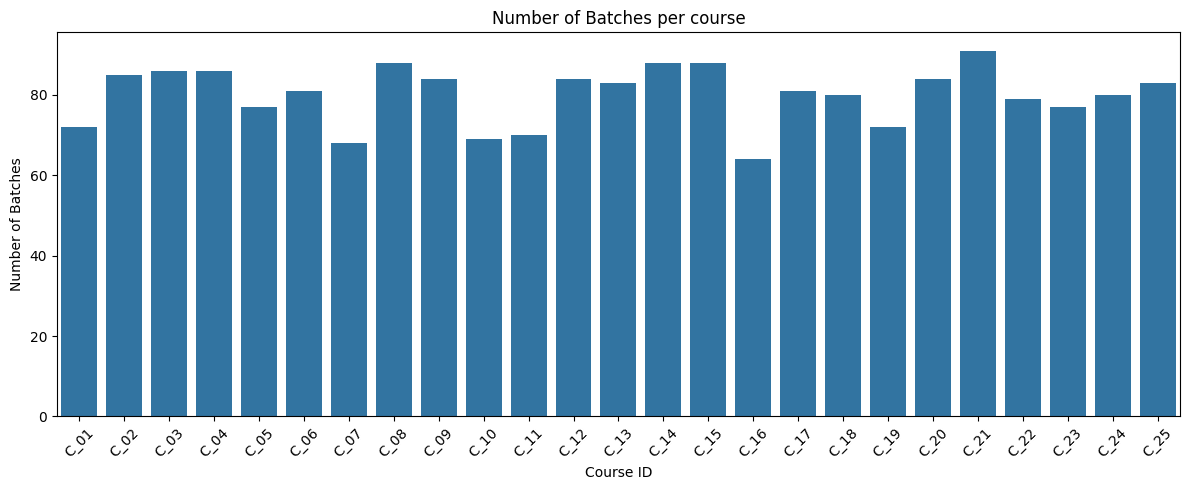

In [50]:
plt.figure(figsize=(12, 5))
sns.barplot(
    x=course_counts.index,
    y= course_counts.values
)
plt.title("Number of Batches per course")
plt.xlabel("Course ID")
plt.ylabel("Number of Batches")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 3. Exploratory Data Analysis (EDA)

Exploratory Data Analysis is performed to understand the distribution, variability, and relationships among the variables before constructing the instructor effectiveness score.

The analysis focuses on:

- Distribution of learner outcome metrics
- Distribution of engagement metrics
- Distribution of feedback metrics
- Potential outliers and boundary values
- Correlations between variables
- Relationships between important learner outcome, engagement, and feedback measures
- Instructor and course-level patterns

In [51]:
outcome_features = [
    "completion_rate",
    "dropout_rate",
    "avg_score_improvement",
    "avg_quiz_score"
]

engagement_features = [
    "avg_watch_time",
    "assignment_submission_rate",
    "forum_activity_rate"
]

feedback_features = [
    "avg_feedback_score",
    "feedback_response_rate"
]

### 3.1 Distribution of Learner Outcome Metrics

The learner outcome variables describe completion, dropout, learning improvement, and quiz performance across course batches.

Understanding their distributions helps identify typical batch behavior, variability, and potential unusual observations.

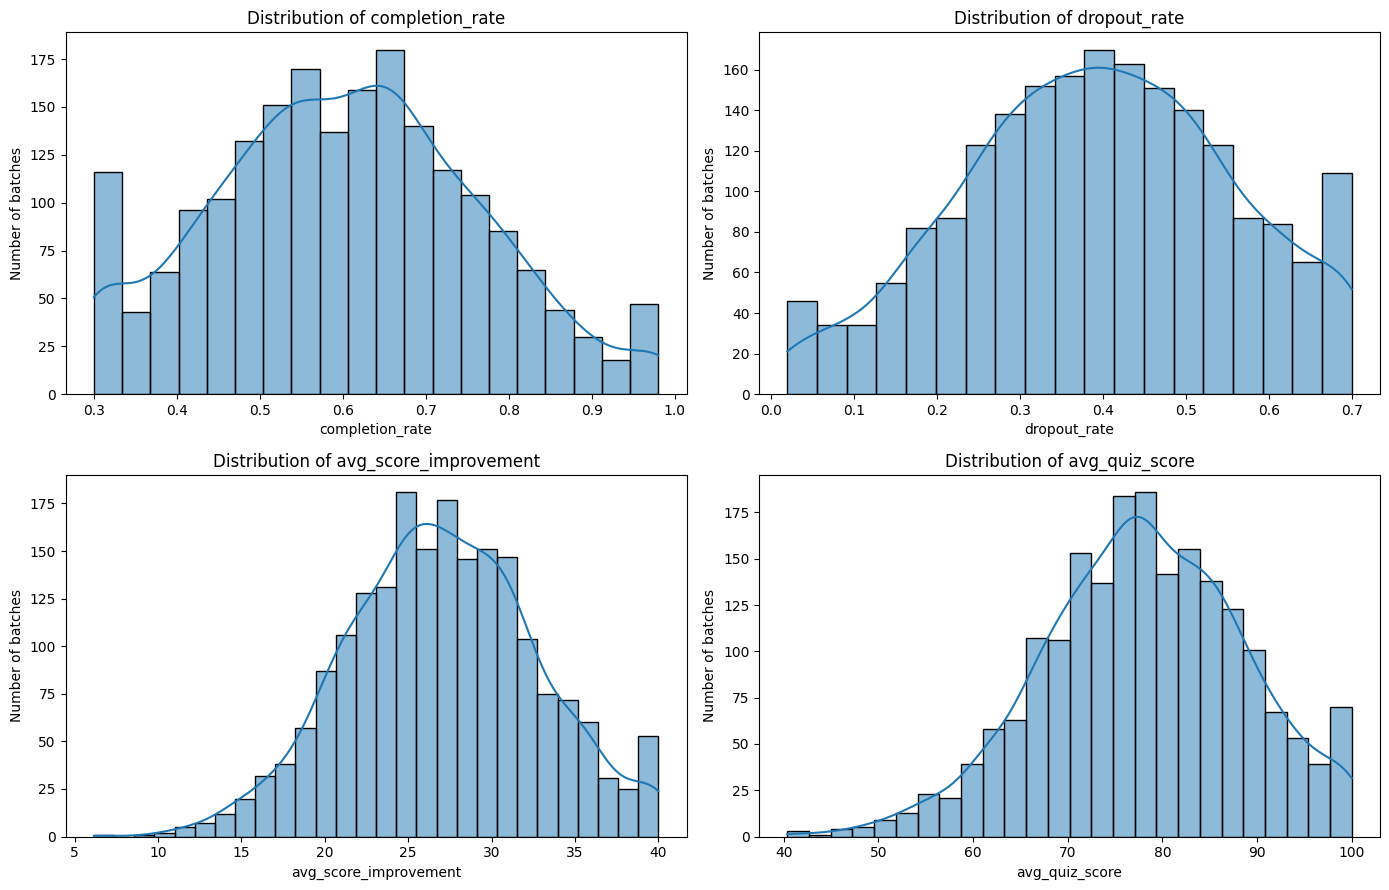

In [52]:
fig, axes = plt.subplots(2, 2, figsize=(14,9))
for ax, feature in zip(axes.flatten(), outcome_features):
    sns.histplot(data=df, x=feature, kde=True, ax=ax)
    ax.set_title(f"Distribution of {feature}")
    ax.set_xlabel(feature)
    ax.set_ylabel("Number of batches")

plt.tight_layout()
plt.show()


### 3.2 Distribution of Engagement Metrics

Engagement metrics capture learner participation and interaction with the course content.

These distributions help us understand whether engagement levels are generally consistent across batches or vary substantially between batches.

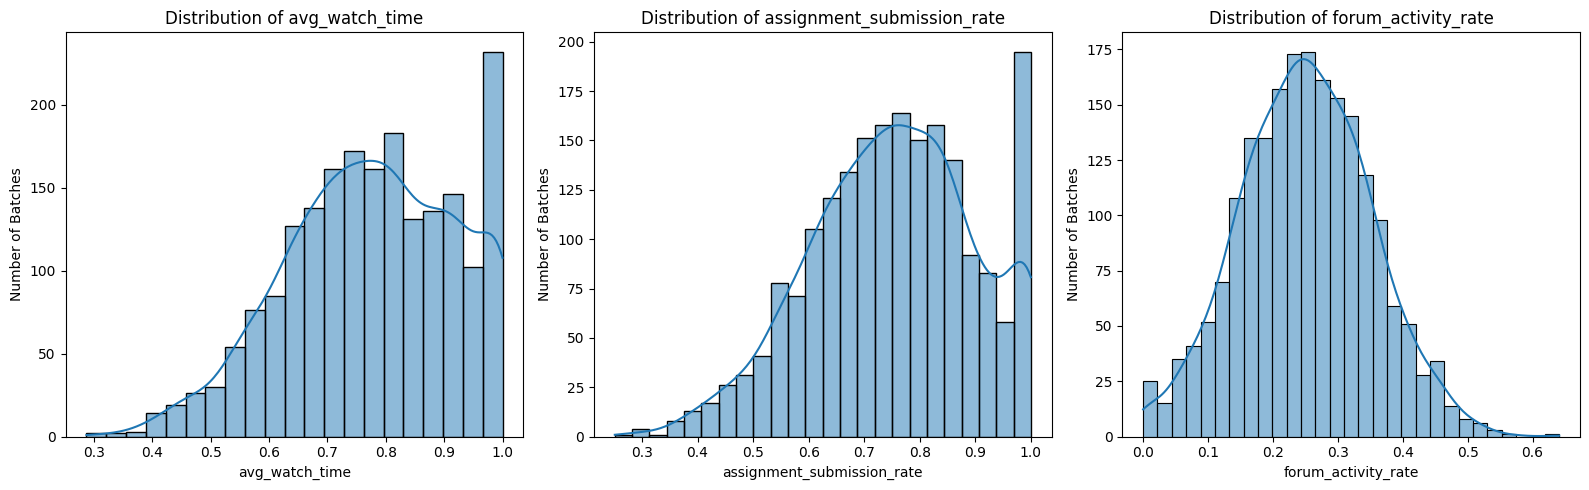

In [53]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, feature in zip(axes, engagement_features):
    sns.histplot(data=df, x=feature, kde=True, ax=ax)
    ax.set_title(f"Distribution of {feature}")
    ax.set_xlabel(feature)
    ax.set_ylabel("Number of Batches")

plt.tight_layout()
plt.show()

### 3.3 Distribution of Feedback Metrics

Feedback metrics represent learner perceptions and the proportion of learners who provided feedback.

The analysis considers both the average feedback rating and the feedback response rate, as these represent different aspects of learner feedback.

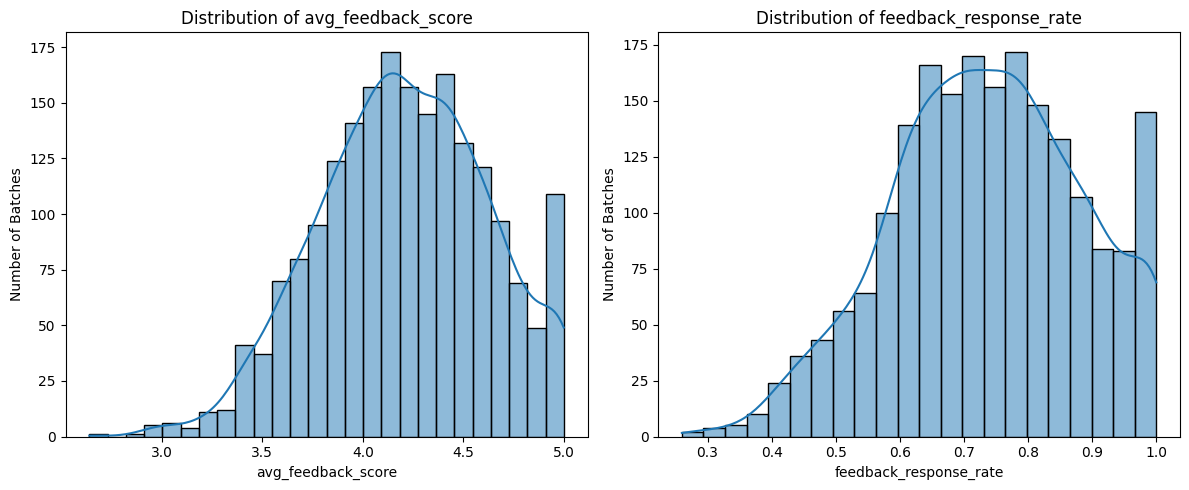

In [54]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, feature in zip(axes, feedback_features):
    sns.histplot(data=df, x=feature, kde=True, ax=ax)
    ax.set_title(f"Distribution of {feature}")
    ax.set_xlabel(feature)
    ax.set_ylabel("Number of Batches")

plt.tight_layout()
plt.show()

### 3.4 Outlier and Range Analysis

Boxplots are used to examine the spread of numerical variables and identify observations that may be statistically unusual.

Potential outliers are not automatically removed. An observation can be statistically unusual while still representing a valid real-world batch, so any treatment will depend on the context of the variable.

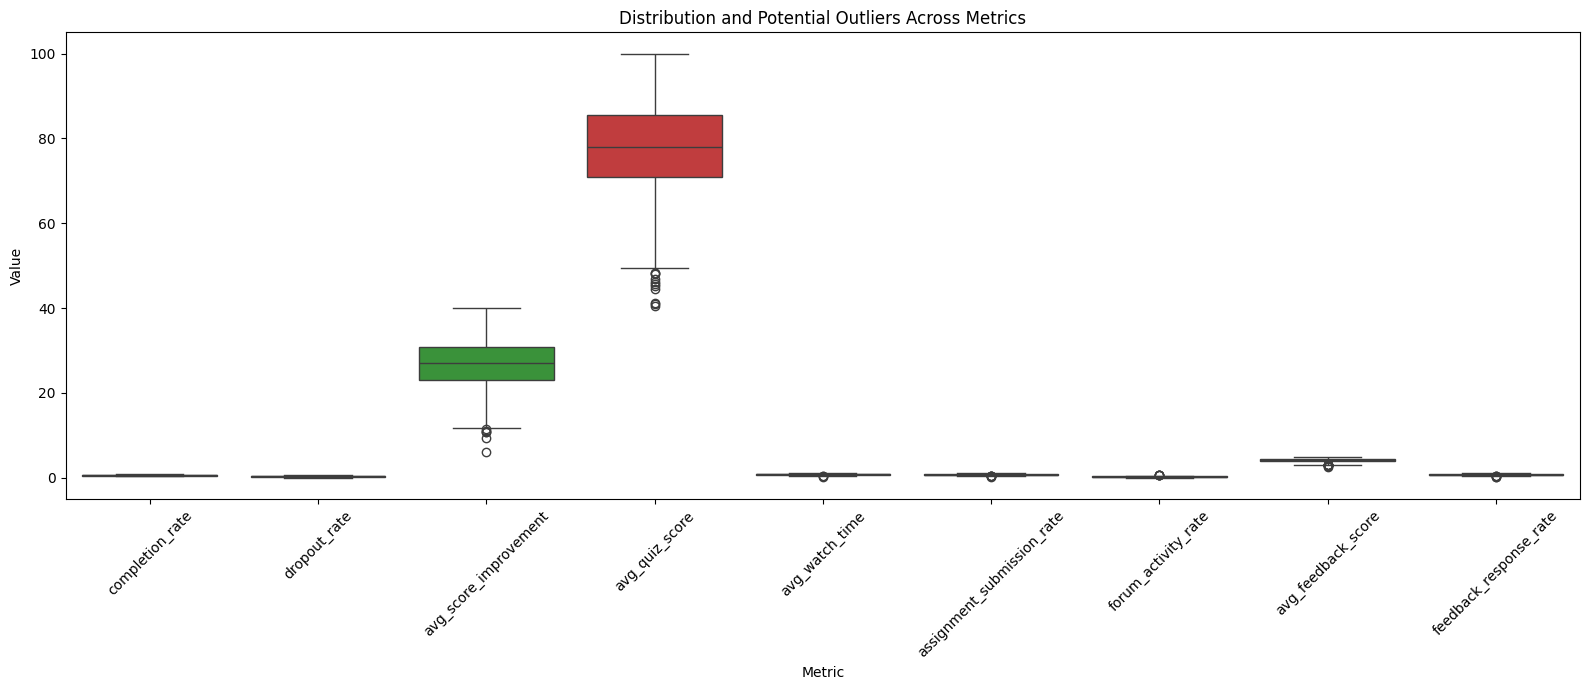

In [55]:
all_metric_features = outcome_features + engagement_features + feedback_features
plt.figure(figsize=(16, 7))
sns.boxplot(data=df[all_metric_features])
plt.xticks(rotation=45)
plt.title("Distribution and Potential Outliers Across Metrics")
plt.xlabel("Metric")
plt.ylabel("Value")
plt.tight_layout()
plt.show()

In [56]:
range_summary = pd.DataFrame({
    "Minimum": df[all_metric_features].min(),
    "Maximum": df[all_metric_features].max(),
    "Mean": df[all_metric_features].mean(),
    "Median": df[all_metric_features].median(),
    "Std Dev": df[all_metric_features].std()
}).round(3)

range_summary

,Minimum,Maximum,Mean,Median,Std Dev
completion_rate,0.300,0.980,0.603,0.603,0.160
dropout_rate,0.020,0.700,0.395,0.395,0.163
avg_score_improvement,6.159,40.000,27.036,26.939,5.717
avg_quiz_score,40.387,100.000,77.956,78.021,10.696
avg_watch_time,0.287,1.000,0.777,0.780,0.145
assignment_submission_rate,0.251,1.000,0.753,0.756,0.148
forum_activity_rate,0.000,0.641,0.250,0.250,0.101
avg_feedback_score,2.640,5.000,4.207,4.206,0.419
feedback_response_rate,0.260,1.000,0.737,0.737,0.149


In [57]:
bounded_features = [
    "completion_rate",
    "dropout_rate",
    "avg_watch_time",
    "assignment_submission_rate",
    "forum_activity_rate",
    "feedback_response_rate"
]

boundary_summary = pd.DataFrame({
    "Minimum": df[bounded_features].min(),
    "Maximum": df[bounded_features].max()
})

boundary_summary

,Minimum,Maximum
completion_rate,0.300000,0.980000
dropout_rate,0.020000,0.700000
avg_watch_time,0.287440,1.000000
assignment_submission_rate,0.251111,1.000000
forum_activity_rate,0.000000,0.641111
feedback_response_rate,0.259935,1.000000


### 3.5 Correlation Analysis

Correlation analysis is used to examine the strength and direction of linear relationships between the numerical metrics.

This helps identify variables that move together and potential redundancy between features. Correlation does not imply causation and is therefore treated as an exploratory tool rather than evidence of causal relationships.

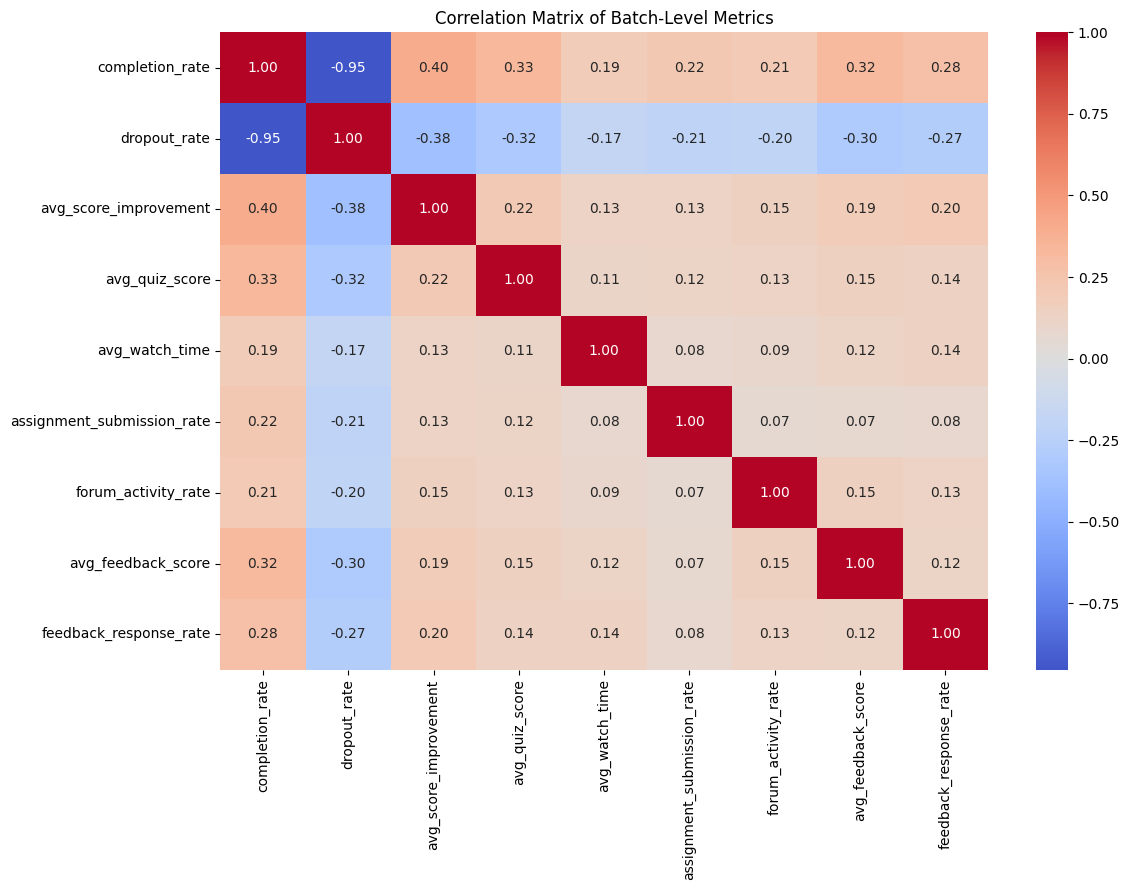

In [58]:
correlation_matrix = df[all_metric_features].corr()
plt.figure(figsize=(12, 9))
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)
plt.title("Correlation Matrix of Batch-Level Metrics")
plt.tight_layout()
plt.show()

In [59]:
correlation_pairs = (
    correlation_matrix
    .where(np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool))
    .stack()
    .sort_values(key=abs, ascending=False)
)

correlation_pairs.head(10)

completion_rate  dropout_rate                 -0.953493
                 avg_score_improvement         0.404161
dropout_rate     avg_score_improvement        -0.381354
completion_rate  avg_quiz_score                0.333307
                 avg_feedback_score            0.315394
dropout_rate     avg_quiz_score               -0.315220
                 avg_feedback_score           -0.300556
completion_rate  feedback_response_rate        0.279549
dropout_rate     feedback_response_rate       -0.274475
completion_rate  assignment_submission_rate    0.221877
dtype: float64

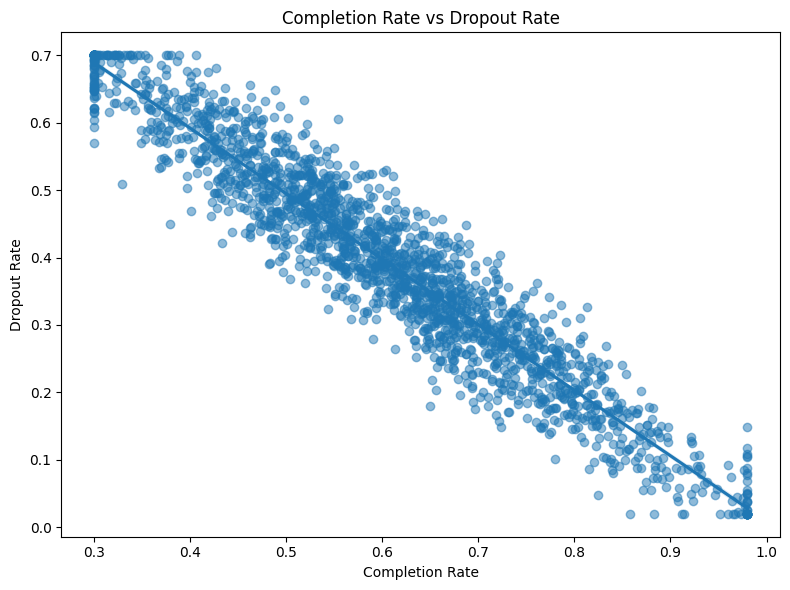

In [60]:
plt.figure(figsize=(8, 6))

sns.regplot(
    data=df,
    x="completion_rate",
    y="dropout_rate",
    scatter_kws={"alpha": 0.5}
)

plt.title("Completion Rate vs Dropout Rate")
plt.xlabel("Completion Rate")
plt.ylabel("Dropout Rate")

plt.tight_layout()
plt.show()

In [61]:
completion_dropout_sum = df["completion_rate"] + df["dropout_rate"]

print("Mean:", completion_dropout_sum.mean())
print("Minimum:", completion_dropout_sum.min())
print("Maximum:", completion_dropout_sum.max())
print(
    "Rows where completion + dropout > 1:",
    (completion_dropout_sum > 1).sum()
)

Mean: 0.9976915409760267
Minimum: 0.828710232358316
Maximum: 1.160438430335401
Rows where completion + dropout > 1: 937


### Completion Rate and Dropout Rate
"Completion rate and dropout rate show a very strong negative relationship. However, their values do not always sum to one, so they are treated as separate reported metrics rather than mathematically complementary categories."

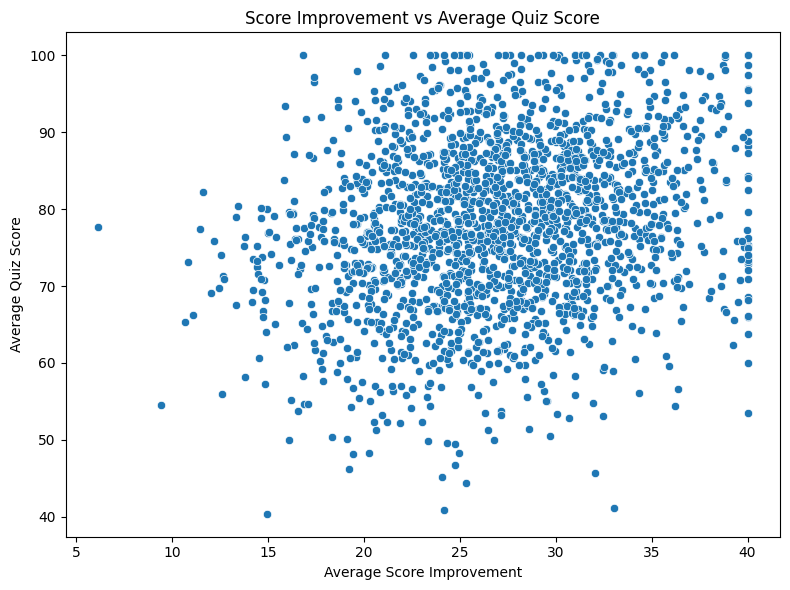

In [62]:
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=df,
    x="avg_score_improvement",
    y="avg_quiz_score"
)
plt.title("Score Improvement vs Average Quiz Score")
plt.xlabel("Average Score Improvement")
plt.ylabel("Average Quiz Score")

plt.tight_layout()
plt.show()

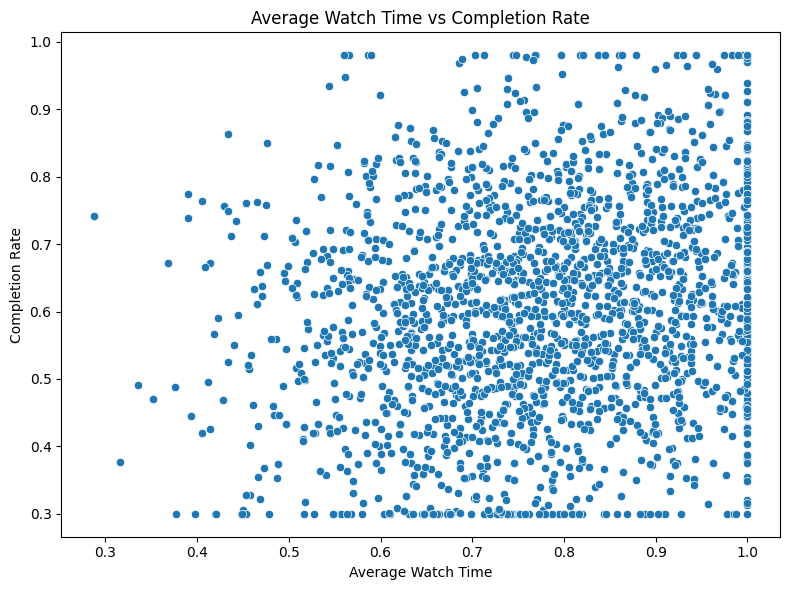

In [63]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df,
    x="avg_watch_time",
    y="completion_rate"
)

plt.title("Average Watch Time vs Completion Rate")
plt.xlabel("Average Watch Time")
plt.ylabel("Completion Rate")

plt.tight_layout()
plt.show()

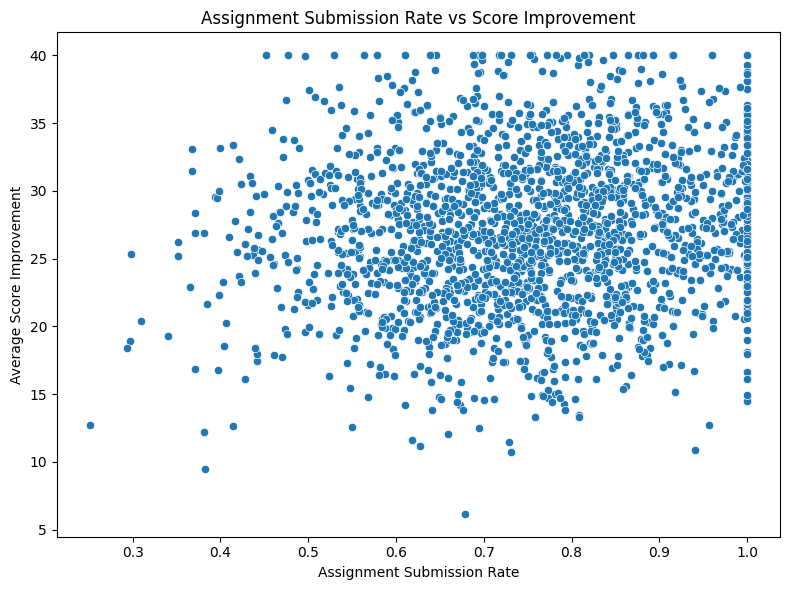

In [64]:
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=df,
    x="assignment_submission_rate",
    y="avg_score_improvement"
)
plt.title("Assignment Submission Rate vs Score Improvement")
plt.xlabel("Assignment Submission Rate")
plt.ylabel("Average Score Improvement")
plt.tight_layout()
plt.show()

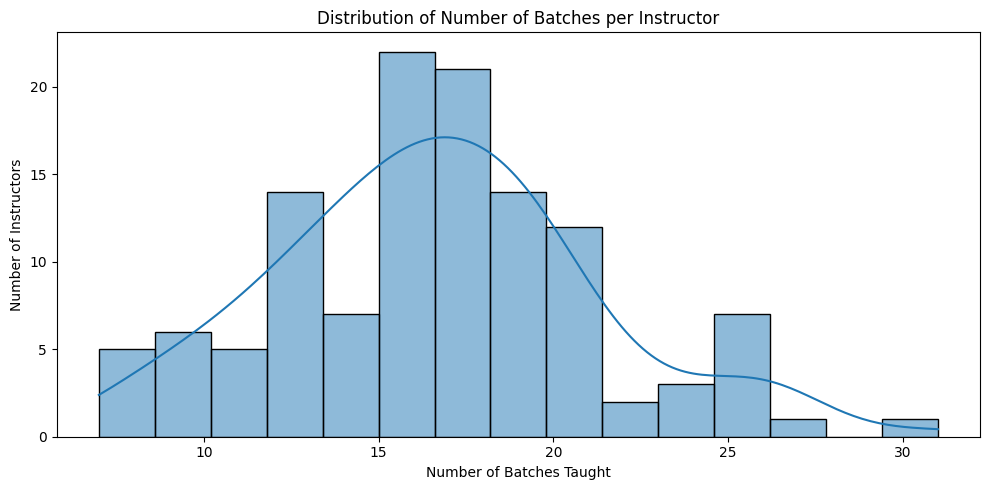

In [65]:
plt.figure(figsize=(10, 5))

sns.histplot(
    instructor_batch_counts,
    bins=15,
    kde=True
)

plt.title("Distribution of Number of Batches per Instructor")
plt.xlabel("Number of Batches Taught")
plt.ylabel("Number of Instructors")

plt.tight_layout()
plt.show()

### 3.6 Initial EDA Findings

Based on the exploratory analysis:

- The dataset contains multiple batches per instructor, allowing batch-level information to be aggregated into instructor-level measures.
- Learner outcome, engagement, and feedback metrics show different ranges and distributions, so direct addition of raw features would not be appropriate when constructing an effectiveness score.
- Completion rate and dropout rate have a very strong negative correlation (approximately -0.95), indicating substantial overlap in the information captured by the two variables.
- The metrics are measured on different scales, including rates between 0 and 1, feedback scores on a 1–5 scale, and quiz scores on a larger numerical scale.
- Some variables contain valid boundary values, such as normalized rates reaching 1 or feedback scores reaching 5. These values should not automatically be treated as erroneous.
- Correlations between engagement, learner outcomes, and feedback provide useful exploratory evidence, but they do not establish causal relationships.
- Course-level and batch-level factors may influence learner outcomes independently of instructor effectiveness and should therefore be considered when interpreting the results.

## 4. Designing the Instructor Effectiveness Score

### 4.1 Definition of Instructor Effectiveness

Instructor effectiveness is defined as a multidimensional measure of an instructor's observed performance across three complementary areas:

1. **Learner Outcomes** – whether learners complete the course, remain engaged through the course, improve their assessment performance, and achieve strong quiz results.
2. **Learner Engagement** – the extent to which learners actively interact with and participate in the course.
3. **Learner Feedback** – learners' reported satisfaction and participation in the feedback process.

Therefore, an effective instructor is considered to be an instructor whose batches demonstrate strong learner outcomes, healthy learner engagement, and positive learner feedback.

The effectiveness score should be interpreted as an estimate based on the available batch-level indicators, rather than as an absolute measure of teaching quality.

---

### 4.2 Instructor-Level Aggregation

The original dataset contains one observation per course batch. Since the final objective is to evaluate instructors, the batch-level observations will first be aggregated to the instructor level.

For the primary analysis, the **mean** of each metric across an instructor's batches will be used.

The mean is selected because:

- Each batch represents an observed instance of an instructor's performance.
- It provides a direct measure of the instructor's average observed performance across batches.
- It is simple and transparent to interpret.
- The dataset does not provide learner counts or batch sizes that could support a meaningful learner-weighted average.

The **median** aggregation will additionally be evaluated as a sensitivity analysis to determine whether the results are strongly affected by unusually high or low batch-level observations.

A weighted mean will not be used in the primary analysis because no defensible batch-size or learner-count variable is available in the provided dataset.

---

### 4.3 Normalization

The instructor-level metrics have different units and ranges. For example, completion rate and engagement rates are proportions, while quiz scores, feedback scores, and score improvement are measured on different numerical scales.

To make the metrics comparable, **Min-Max normalization** will be applied:

\[
X_{normalized} =
\frac{X - X_{min}}
{X_{max} - X_{min}}
\]

This transforms each metric to a common range of 0 to 1.

A normalized value closer to 1 represents relatively stronger performance within the observed instructor population.

Therefore, the final effectiveness score represents **relative performance among the instructors in this dataset**, rather than an absolute measure of teaching quality.

---

### 4.4 Direction of Metrics

Most metrics have a positive relationship with effectiveness, meaning that higher values indicate better performance.

These include:

- `completion_rate`
- `avg_score_improvement`
- `avg_quiz_score`
- `avg_watch_time`
- `assignment_submission_rate`
- `forum_activity_rate`
- `avg_feedback_score`
- `feedback_response_rate`

However, `dropout_rate` is a negative metric because a lower dropout rate is preferable.

Therefore, after normalization, the direction of dropout will be reversed:

\[
DropoutScore = 1 - DropoutNormalized
\]

This ensures that higher values consistently represent better performance across all components of the effectiveness score.

---

### 4.5 Learner Outcomes Dimension

Learner outcomes are divided into three concepts:

#### Retention

Completion and dropout both describe learner retention. During EDA, these two variables were found to have a very strong negative relationship. Treating them as completely independent components could therefore give retention disproportionate influence.

A combined retention score will be calculated as:

\[
RetentionScore =
\frac{CompletionScore + DropoutScore}{2}
\]

#### Learning Gain

`avg_score_improvement` captures the average change in learner performance between the beginning and end of the learning experience.

#### Quiz Performance

`avg_quiz_score` represents the average level of learner performance on quizzes.

The overall Learner Outcomes score will therefore be:

\[
OutcomeScore =
\frac{
RetentionScore +
ScoreImprovementScore +
QuizScore
}{3}
\]

---

### 4.6 Learner Engagement Dimension

Learner engagement is represented by:

- `avg_watch_time`
- `assignment_submission_rate`
- `forum_activity_rate`

These represent different forms of learner participation, ranging from content consumption to active participation.

The Engagement score will be calculated as:

\[
EngagementScore =
\frac{
WatchTimeScore +
AssignmentSubmissionScore +
ForumActivityScore
}{3}
\]

---

### 4.7 Learner Feedback Dimension

Learner feedback is represented by:

- `avg_feedback_score`
- `feedback_response_rate`

Both metrics will be included because they are explicitly provided as feedback-related indicators in the dataset.

`avg_feedback_score` represents the reported learner rating, while `feedback_response_rate` indicates the proportion of learners who participated in providing feedback.

The Feedback score will therefore be:

\[
FeedbackScore =
\frac{
FeedbackRatingScore +
FeedbackResponseScore
}{2}
\]

Feedback response rate will also be interpreted as a measure of feedback coverage. A high feedback score based on a very small response rate should therefore be interpreted with caution.

---

### 4.8 Dimension Weighting

The three dimensions represent complementary aspects of instructor effectiveness:

- Learner Outcomes
- Learner Engagement
- Learner Feedback

Since the dataset does not provide external business-defined weights or a ground-truth instructor effectiveness label, assigning highly specific weights would introduce subjective assumptions.

Therefore, the three dimensions will receive equal weights:

- Learner Outcomes: **33.33%**
- Learner Engagement: **33.33%**
- Learner Feedback: **33.33%**

The final Instructor Effectiveness Score will be:

\[
\boxed{
EffectivenessScore =
\frac{
OutcomeScore +
EngagementScore +
FeedbackScore
}{3}
}
\]

The resulting score will range from approximately 0 to 1, where higher values indicate stronger relative performance across the three dimensions.

---

### 4.9 Important Assumptions and Limitations

The effectiveness score is an analytical estimate based on the available dataset and should not be interpreted as a definitive measure of instructor quality.

Several factors may influence the observed metrics but are not explicitly controlled for in the dataset, including:

- Course difficulty
- Learner characteristics
- Cohort composition
- Assessment difficulty
- Course structure
- Learner motivation
- Other platform or operational factors

Therefore, the score measures **observed instructor-associated performance** rather than proving that an instructor is solely responsible for the observed learner outcomes.

The score is intended to provide a consistent and interpretable basis for comparing instructors within the observed dataset.

### 4.10 Creating the Instructor-Level Dataset

The original dataset contains one row per course batch. Since the effectiveness score is intended to evaluate instructors, the batch-level observations will be aggregated using `instructor_id`.

For the primary analysis, the mean value of each effectiveness metric across all batches taught by an instructor will be calculated.

The number of batches taught by each instructor will also be retained as `num_batches`. This provides useful context about the amount of observed data supporting each instructor's effectiveness estimate, but it will not directly contribute to the effectiveness score.

In [66]:
effectiveness_metrics = [
    "completion_rate",
    "dropout_rate",
    "avg_score_improvement",
    "avg_quiz_score",
    "avg_watch_time",
    "assignment_submission_rate",
    "forum_activity_rate",
    "avg_feedback_score",
    "feedback_response_rate"
]

In [67]:
instructor_df = (
    df.groupby("instructor_id")[effectiveness_metrics]
      .mean()
      .reset_index()
)

instructor_df.head()

,instructor_id,completion_rate,dropout_rate,avg_score_improvement,avg_quiz_score,avg_watch_time,assignment_submission_rate,forum_activity_rate,avg_feedback_score,feedback_response_rate
0,I_001,0.543887,0.470593,26.641462,78.900194,0.766513,0.726893,0.240551,4.217743,0.694858
1,I_002,0.730874,0.247194,30.166242,81.737198,0.837393,0.774394,0.289610,4.343002,0.784338
2,I_003,0.768447,0.234828,29.977813,81.590928,0.818441,0.779606,0.296224,4.450034,0.812132
3,I_004,0.458328,0.547261,22.912021,77.680317,0.793130,0.758317,0.226259,4.076410,0.721460
4,I_005,0.859747,0.145733,32.588652,85.828159,0.847026,0.876942,0.333519,4.202516,0.784197


In [68]:
batch_counts = (
    df.groupby("instructor_id")["batch_id"]
      .nunique()
      .reset_index(name="num_batches")
)

batch_counts.head()

,instructor_id,num_batches
0,I_001,25
1,I_002,20
2,I_003,18
3,I_004,17
4,I_005,19


In [69]:
instructor_df = instructor_df.merge(
    batch_counts,
    on="instructor_id",
    how="left"
)

instructor_df.head()

,instructor_id,completion_rate,dropout_rate,avg_score_improvement,avg_quiz_score,avg_watch_time,assignment_submission_rate,forum_activity_rate,avg_feedback_score,feedback_response_rate,num_batches
0,I_001,0.543887,0.470593,26.641462,78.900194,0.766513,0.726893,0.240551,4.217743,0.694858,25
1,I_002,0.730874,0.247194,30.166242,81.737198,0.837393,0.774394,0.289610,4.343002,0.784338,20
2,I_003,0.768447,0.234828,29.977813,81.590928,0.818441,0.779606,0.296224,4.450034,0.812132,18
3,I_004,0.458328,0.547261,22.912021,77.680317,0.793130,0.758317,0.226259,4.076410,0.721460,17
4,I_005,0.859747,0.145733,32.588652,85.828159,0.847026,0.876942,0.333519,4.202516,0.784197,19


### 4.11 Validating the Instructor-Level Aggregation

Before calculating the effectiveness score, the aggregated dataset will be validated to ensure that:

- Each instructor appears exactly once.
- The number of instructors matches the number of unique instructors in the original dataset.
- No instructor has an invalid batch count.
- The aggregated effectiveness metrics do not contain unexpected missing values.

In [70]:
print("Original number of unique instructors:", df["instructor_id"].nunique())
print("Number of rows in instructor_df:", len(instructor_df))
print("Duplicate instructor IDs:", instructor_df["instructor_id"].duplicated().sum())
print("Minimum batches per instructor:", instructor_df["num_batches"].min())
print("Maximum batches per instructor:", instructor_df["num_batches"].max())

Original number of unique instructors: 120
Number of rows in instructor_df: 120
Duplicate instructor IDs: 0
Minimum batches per instructor: 7
Maximum batches per instructor: 31


In [71]:
instructor_df[effectiveness_metrics + ["num_batches"]].isnull().sum()

completion_rate               0
dropout_rate                  0
avg_score_improvement         0
avg_quiz_score                0
avg_watch_time                0
assignment_submission_rate    0
forum_activity_rate           0
avg_feedback_score            0
feedback_response_rate        0
num_batches                   0
dtype: int64

In [72]:
instructor_df.shape

(120, 11)

In [73]:
instructor_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 11 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   instructor_id               120 non-null    object 
 1   completion_rate             120 non-null    float64
 2   dropout_rate                120 non-null    float64
 3   avg_score_improvement       120 non-null    float64
 4   avg_quiz_score              120 non-null    float64
 5   avg_watch_time              120 non-null    float64
 6   assignment_submission_rate  120 non-null    float64
 7   forum_activity_rate         120 non-null    float64
 8   avg_feedback_score          120 non-null    float64
 9   feedback_response_rate      120 non-null    float64
 10  num_batches                 120 non-null    int64  
dtypes: float64(9), int64(1), object(1)
memory usage: 10.4+ KB


### 4.12 Inspecting Instructor-Level Metric Ranges

Before normalization, the distributions and ranges of the instructor-level metrics are inspected to confirm that the variables are measured on different scales and to identify the minimum and maximum values that will be used for Min-Max normalization.

In [74]:
instructor_df[effectiveness_metrics].describe().T

,count,mean,std,min,25%,50%,75%,max
completion_rate,120.0,0.602577,0.132049,0.313393,0.524226,0.599075,0.676031,0.940783
dropout_rate,120.0,0.394890,0.127827,0.068522,0.319625,0.399884,0.478089,0.664304
avg_score_improvement,120.0,27.081173,3.262537,18.792529,24.794550,27.186671,29.094976,34.856747
avg_quiz_score,120.0,77.816949,5.203223,62.635548,74.299329,78.420367,80.754386,91.071769
avg_watch_time,120.0,0.775987,0.048667,0.655381,0.745444,0.779371,0.804021,0.903739
assignment_submission_rate,120.0,0.751371,0.059035,0.559471,0.714699,0.753619,0.788984,0.924766
forum_activity_rate,120.0,0.250760,0.038249,0.126935,0.228253,0.249723,0.273528,0.343266
avg_feedback_score,120.0,4.204834,0.184735,3.733388,4.091261,4.203793,4.329868,4.641986
feedback_response_rate,120.0,0.734985,0.061948,0.589527,0.688954,0.742063,0.784232,0.891873


### 4.13 Min-Max Normalization

Min-Max normalization is applied to transform each effectiveness metric to a common 0–1 scale.

The transformation is:

\[
X_{normalized} =
\frac{X - X_{min}}
{X_{max} - X_{min}}
\]

After normalization:

- The minimum observed value becomes 0.
- The maximum observed value becomes 1.
- Values between the minimum and maximum are proportionally scaled between 0 and 1.

This allows metrics with different units and ranges to be combined into the effectiveness dimensions.

In [75]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()

normalized_values = scaler.fit_transform(
    instructor_df[effectiveness_metrics]
)

normalized_df = pd.DataFrame(
    normalized_values,
    columns=effectiveness_metrics,
    index=instructor_df.index
)

normalized_df.head()

,completion_rate,dropout_rate,avg_score_improvement,avg_quiz_score,avg_watch_time,assignment_submission_rate,forum_activity_rate,avg_feedback_score,feedback_response_rate
0,0.367386,0.674863,0.488597,0.571969,0.447467,0.458320,0.525194,0.533079,0.348378
1,0.665425,0.299896,0.708015,0.671737,0.732860,0.588355,0.751970,0.670940,0.644331
2,0.725311,0.279139,0.696286,0.666593,0.656554,0.602625,0.782544,0.788738,0.736259
3,0.231012,0.803548,0.256439,0.529071,0.554639,0.544343,0.459130,0.377529,0.436363
4,0.870836,0.129597,0.858811,0.815601,0.771647,0.869081,0.954941,0.516321,0.643863


### 4.14 Reversing the Direction of Dropout Rate

`dropout_rate` is a negative indicator because a lower dropout rate represents better learner retention.

Min-Max normalization alone would assign higher normalized values to instructors with higher dropout rates. Therefore, the normalized dropout metric is reversed:

\[
DropoutScore = 1 - DropoutNormalized
\]

After this transformation, higher values consistently represent better performance across all metrics.

In [76]:
normalized_df["dropout_score"] = (
    1 - normalized_df["dropout_rate"]
).clip(0, 1)

normalized_df = normalized_df.drop(columns=["dropout_rate"])

normalized_df.head()

,completion_rate,avg_score_improvement,avg_quiz_score,avg_watch_time,assignment_submission_rate,forum_activity_rate,avg_feedback_score,feedback_response_rate,dropout_score
0,0.367386,0.488597,0.571969,0.447467,0.458320,0.525194,0.533079,0.348378,0.325137
1,0.665425,0.708015,0.671737,0.732860,0.588355,0.751970,0.670940,0.644331,0.700104
2,0.725311,0.696286,0.666593,0.656554,0.602625,0.782544,0.788738,0.736259,0.720861
3,0.231012,0.256439,0.529071,0.554639,0.544343,0.459130,0.377529,0.436363,0.196452
4,0.870836,0.858811,0.815601,0.771647,0.869081,0.954941,0.516321,0.643863,0.870403


### 4.15 Constructing the Learner Outcomes Score

The Learner Outcomes dimension captures the extent to which learners successfully progress through the learning experience and demonstrate learning.

It consists of three components:

1. **Retention** – represented by completion rate and the reversed dropout score.
2. **Learning Gain** – represented by average score improvement.
3. **Assessment Performance** – represented by average quiz score.

Completion and dropout are combined into a single Retention Score because they measure closely related aspects of learner retention. This prevents retention from receiving disproportionate weight simply because it is represented by two highly related variables.

The Retention Score is calculated as:

\[
RetentionScore =
\frac{CompletionScore + DropoutScore}{2}
\]

The overall Learner Outcomes Score is then calculated as:

\[
OutcomeScore =
\frac{
RetentionScore +
ScoreImprovementScore +
QuizScore
}{3}
\]

Equal weighting is used within the dimension because no external evidence is available to justify assigning greater importance to one component.

In [77]:
normalized_df["retention_score"] = (
    normalized_df["completion_rate"] +
    normalized_df["dropout_score"]
) / 2

In [78]:
normalized_df["outcome_score"] = (
    normalized_df["retention_score"] +
    normalized_df["avg_score_improvement"] +
    normalized_df["avg_quiz_score"]
) / 3

In [79]:
normalized_df["outcome_score"].describe()

count    120.000000
mean       0.502137
std        0.187623
min        0.018319
25%        0.393438
50%        0.504268
75%        0.604815
max        0.995132
Name: outcome_score, dtype: float64

### 4.16 Constructing the Learner Engagement Score

The Learner Engagement dimension captures different forms of learner participation in the course.

It consists of:

- `avg_watch_time` – learner interaction with course content
- `assignment_submission_rate` – learner participation in assigned work
- `forum_activity_rate` – learner participation in course discussions

Since these metrics represent different aspects of engagement and no external evidence is available to justify different weights, they are equally weighted.

The Engagement Score is calculated as:

\[
EngagementScore =
\frac{
WatchTimeScore +
AssignmentSubmissionScore +
ForumActivityScore
}{3}
\]

In [80]:
normalized_df["engagement_score"] = (
    normalized_df["avg_watch_time"] +
    normalized_df["assignment_submission_rate"] +
    normalized_df["forum_activity_rate"]
) / 3

In [81]:
normalized_df["engagement_score"].describe()

count    120.000000
mean       0.527775
std        0.147561
min        0.106373
25%        0.439955
50%        0.516564
75%        0.612470
max        0.916525
Name: engagement_score, dtype: float64

### 4.17 Constructing the Learner Feedback Score

The Learner Feedback dimension combines two feedback-related indicators:

- `avg_feedback_score` – the average rating provided by learners.
- `feedback_response_rate` – the proportion of learners who provided feedback.

The feedback score measures the reported learner experience, while the response rate provides information about the coverage of the feedback.

Both metrics are equally weighted because no external evidence is available to justify assigning a greater weight to either measure.

The Feedback Score is calculated as:

\[
FeedbackScore =
\frac{
FeedbackRatingScore +
FeedbackResponseScore
}{2}
\]

The response rate will also be considered when interpreting feedback results. A high average feedback score based on a low response rate should be interpreted with greater caution because the feedback represents a smaller proportion of learners.

In [82]:
normalized_df["feedback_score"] = (
    normalized_df["avg_feedback_score"] +
    normalized_df["feedback_response_rate"]
) / 2

In [83]:
normalized_df["feedback_score"].describe()

count    120.000000
mean       0.499985
std        0.190798
min        0.000000
25%        0.382332
50%        0.481143
75%        0.649430
max        0.961531
Name: feedback_score, dtype: float64

In [84]:
dimension_scores = instructor_df[["instructor_id"]].copy()
dimension_scores["outcome_score"] = normalized_df["outcome_score"]
dimension_scores["engagement_score"] = normalized_df["engagement_score"]
dimension_scores["feedback_score"] = normalized_df["feedback_score"]

dimension_scores.head()

,instructor_id,outcome_score,engagement_score,feedback_score
0,I_001,0.468943,0.476994,0.440728
1,I_002,0.687506,0.691062,0.657636
2,I_003,0.695322,0.680574,0.762499
3,I_004,0.333081,0.519371,0.406946
4,I_005,0.848344,0.865223,0.580092


In [85]:
dimension_scores[
    ["outcome_score", "engagement_score", "feedback_score"]
].describe().T

,count,mean,std,min,25%,50%,75%,max
outcome_score,120.0,0.502137,0.187623,0.018319,0.393438,0.504268,0.604815,0.995132
engagement_score,120.0,0.527775,0.147561,0.106373,0.439955,0.516564,0.612470,0.916525
feedback_score,120.0,0.499985,0.190798,0.000000,0.382332,0.481143,0.649430,0.961531


In [86]:
dimension_scores[
    ["outcome_score", "engagement_score", "feedback_score"]
].isnull().sum()

outcome_score       0
engagement_score    0
feedback_score      0
dtype: int64

### 4.18 Final Instructor Effectiveness Score

The final Instructor Effectiveness Score combines the three dimension-level scores:

- Learner Outcomes
- Learner Engagement
- Learner Feedback

Since no external ground-truth effectiveness label or business-defined weighting scheme is available, equal weights are assigned to the three dimensions.

Therefore:

\[
EffectivenessScore =
\frac{
OutcomeScore +
EngagementScore +
FeedbackScore
}{3}
\]

The resulting score lies between 0 and 1, where a higher score indicates stronger relative performance across the three dimensions within the observed instructor population.

The score should be interpreted as a relative analytical measure of observed instructor-associated performance rather than an absolute measure of teaching quality.

In [87]:
dimension_scores["effectiveness_score"] = (
    dimension_scores["outcome_score"] +
    dimension_scores["engagement_score"] +
    dimension_scores["feedback_score"]
) / 3

In [88]:
dimension_scores.head(10)

,instructor_id,outcome_score,engagement_score,feedback_score,effectiveness_score
0,I_001,0.468943,0.476994,0.440728,0.462222
1,I_002,0.687506,0.691062,0.657636,0.678734
2,I_003,0.695322,0.680574,0.762499,0.712798
3,I_004,0.333081,0.519371,0.406946,0.419799
4,I_005,0.848344,0.865223,0.580092,0.764553
5,I_006,0.225304,0.311831,0.260930,0.266022
6,I_007,0.672018,0.668472,0.574603,0.638364
7,I_008,0.568433,0.588336,0.652395,0.603054
8,I_009,0.477209,0.490447,0.619819,0.529158
9,I_010,0.995132,0.916525,0.950833,0.954163


In [89]:
dimension_scores["effectiveness_score"].describe()

count    120.000000
mean       0.509966
std        0.167328
min        0.071626
25%        0.413255
50%        0.510951
75%        0.615011
max        0.954163
Name: effectiveness_score, dtype: float64

In [90]:
print(
    "Minimum effectiveness score:",
    dimension_scores["effectiveness_score"].min()
)

print(
    "Maximum effectiveness score:",
    dimension_scores["effectiveness_score"].max()
)

print(
    "Scores outside [0, 1]:",
    (
        (dimension_scores["effectiveness_score"] < 0) |
        (dimension_scores["effectiveness_score"] > 1)
    ).sum()
)

Minimum effectiveness score: 0.07162564161451514
Maximum effectiveness score: 0.9541633108865967
Scores outside [0, 1]: 0


In [91]:
instructor_scores = (
    instructor_df[
        ["instructor_id", "num_batches"]
    ]
    .merge(
        dimension_scores,
        on="instructor_id",
        how="left"
    )
)

In [92]:
instructor_scores.head()

,instructor_id,num_batches,outcome_score,engagement_score,feedback_score,effectiveness_score
0,I_001,25,0.468943,0.476994,0.440728,0.462222
1,I_002,20,0.687506,0.691062,0.657636,0.678734
2,I_003,18,0.695322,0.680574,0.762499,0.712798
3,I_004,17,0.333081,0.519371,0.406946,0.419799
4,I_005,19,0.848344,0.865223,0.580092,0.764553


In [93]:
print("Rows:", len(instructor_scores))
print(
    "Unique instructors:",
    instructor_scores["instructor_id"].nunique()
)
print(
    "Duplicate instructor IDs:",
    instructor_scores["instructor_id"].duplicated().sum()
)

Rows: 120
Unique instructors: 120
Duplicate instructor IDs: 0


In [94]:
instructor_scores.sort_values(
    "effectiveness_score",
    ascending=False
).head(10)

,instructor_id,num_batches,outcome_score,engagement_score,feedback_score,effectiveness_score
9,I_010,13,0.995132,0.916525,0.950833,0.954163
36,I_037,15,0.931725,0.869059,0.885755,0.895513
17,I_018,14,0.881554,0.901362,0.814347,0.865754
104,I_105,16,0.882580,0.824421,0.830535,0.845845
117,I_118,19,0.837812,0.607231,0.961531,0.802191
90,I_091,8,0.873549,0.704593,0.727489,0.768544
4,I_005,19,0.848344,0.865223,0.580092,0.764553
24,I_025,19,0.777913,0.743078,0.753400,0.758130
14,I_015,17,0.705643,0.798013,0.744220,0.749292
101,I_102,7,0.792241,0.707673,0.715104,0.738339


In [95]:
instructor_scores.sort_values(
    "effectiveness_score",
    ascending=True
).head(10)

,instructor_id,num_batches,outcome_score,engagement_score,feedback_score,effectiveness_score
43,I_044,15,0.018319,0.196558,0.000000,0.071626
74,I_075,19,0.051587,0.106373,0.102468,0.086809
49,I_050,12,0.113286,0.188962,0.089481,0.130576
112,I_113,26,0.166663,0.297449,0.117735,0.193949
73,I_074,17,0.177376,0.307158,0.154128,0.212887
66,I_067,14,0.216418,0.421967,0.082949,0.240444
35,I_036,21,0.258351,0.294769,0.181908,0.245009
82,I_083,10,0.237688,0.174905,0.353978,0.255524
72,I_073,13,0.261737,0.257347,0.278603,0.265896
5,I_006,15,0.225304,0.311831,0.260930,0.266022


### 4.19 Distribution of Instructor Effectiveness Scores

Before assigning effectiveness tiers, the distribution of the continuous effectiveness score is examined.

This helps determine whether the scores are evenly distributed, concentrated within a narrow range, or affected by potential outliers.

The tiering method will be selected after examining the observed score distribution rather than imposing arbitrary thresholds without inspecting the data.

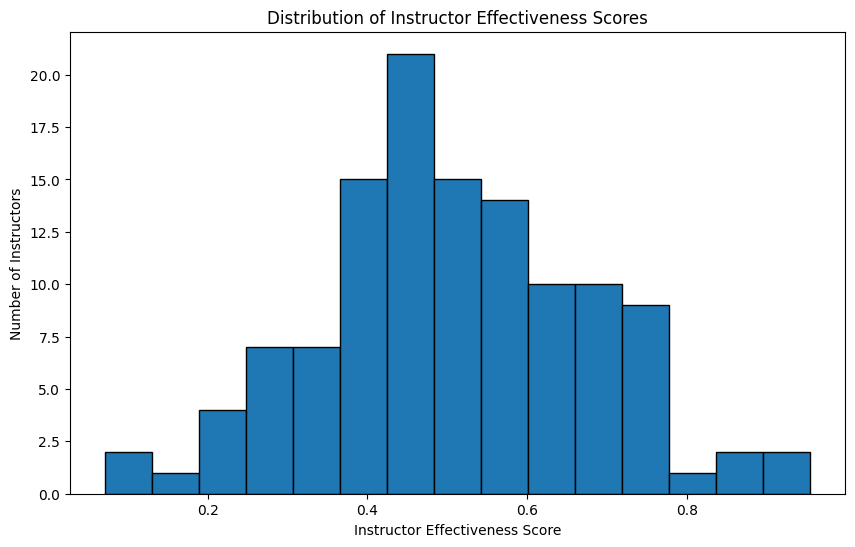

In [96]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.hist(
    instructor_scores["effectiveness_score"],
    bins=15,
    edgecolor="black"
)

plt.xlabel("Instructor Effectiveness Score")
plt.ylabel("Number of Instructors")
plt.title("Distribution of Instructor Effectiveness Scores")

plt.show()

In [97]:
instructor_scores["effectiveness_score"].quantile(
    [0.10, 0.25, 0.50, 0.75, 0.90]
)

0.10    0.276753
0.25    0.413255
0.50    0.510951
0.75    0.615011
0.90    0.721444
Name: effectiveness_score, dtype: float64

### 4.20 Defining Instructor Effectiveness Tiers

The continuous effectiveness score is converted into three categorical tiers:

- Low Effectiveness
- Medium Effectiveness
- High Effectiveness

Because the dataset does not provide externally validated thresholds for defining these categories, fixed score cutoffs would introduce arbitrary assumptions.

The distribution of the effectiveness score was therefore examined before defining the tiers. The score distribution is relatively continuous and does not show clear natural separation points.

Consequently, a quantile-based approach is used. The instructors are divided into approximately three equal-sized groups using the 33rd and 67th percentiles of the effectiveness score.

The resulting interpretation is:

- **Low Effectiveness:** bottom third of observed instructor scores
- **Medium Effectiveness:** middle third
- **High Effectiveness:** top third

This approach provides reasonably balanced target classes for the subsequent classification task while preserving the relative ordering of instructors.

The tiers should be interpreted as relative categories within the observed instructor population, rather than absolute judgments of instructor quality.

In [98]:
tier_boundaries = instructor_scores["effectiveness_score"].quantile(
    [1/3, 2/3]
)

tier_boundaries

0.333333    0.441162
0.666667    0.580505
Name: effectiveness_score, dtype: float64

In [99]:
instructor_scores["effectiveness_tier"] = pd.qcut(
    instructor_scores["effectiveness_score"],
    q=3,
    labels=["Low", "Medium", "High"]
)

In [100]:
instructor_scores["effectiveness_tier"].value_counts()

effectiveness_tier
Low       40
Medium    40
High      40
Name: count, dtype: int64

In [101]:
instructor_scores["effectiveness_tier"].value_counts(
    normalize=True
).mul(100).round(2)

effectiveness_tier
Low       33.33
Medium    33.33
High      33.33
Name: proportion, dtype: float64

In [102]:
instructor_scores.groupby(
    "effectiveness_tier",
    observed=True
)["effectiveness_score"].agg(
    ["count", "min", "mean", "max"]
)

,count,min,mean,max
effectiveness_tier,,,,
Low,40,0.071626,0.333391,0.439724
Medium,40,0.441881,0.503998,0.580051
High,40,0.581413,0.692508,0.954163


### 4.21 Interpretation of Effectiveness Tiers

The effectiveness tiers represent relative performance within the instructor population observed in this dataset.

- **Low:** instructors whose effectiveness scores fall within the bottom third of the observed distribution.
- **Medium:** instructors whose scores fall within the middle third.
- **High:** instructors whose scores fall within the top third.

These labels do not represent externally validated standards of teaching quality. They are derived from the constructed effectiveness score and are intended to provide a practical target variable for the subsequent classification task.

## 5. Machine Learning Model — Predicting Instructor Effectiveness Tier

The effectiveness tier defined in the previous section is treated as the target variable for a multiclass classification problem.

The objective is to predict whether an instructor belongs to the Low, Medium, or High effectiveness tier using the underlying instructor-level performance metrics.

The model will use the nine effectiveness metrics as candidate predictors. Identifier variables such as `instructor_id` and `course_id` are excluded because they do not represent instructor performance.

The derived `effectiveness_score` and dimension-level scores are also excluded from the model features because they were directly constructed from the same metrics used to define the target. Including them would make the model trivially reproduce the target and would not provide meaningful additional information.

`num_batches` is retained as contextual information but is not included in the primary model because the number of batches taught does not directly represent instructor effectiveness and may act as a proxy for experience or exposure.

A stratified train-test split will be used so that the Low, Medium, and High classes remain proportionally represented in both sets.

In [103]:
model_features = effectiveness_metrics

X = instructor_df[model_features].copy()

y = instructor_scores["effectiveness_tier"].copy()

In [104]:
print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

Feature matrix shape: (120, 9)
Target shape: (120,)


In [105]:
X.head()

,completion_rate,dropout_rate,avg_score_improvement,avg_quiz_score,avg_watch_time,assignment_submission_rate,forum_activity_rate,avg_feedback_score,feedback_response_rate
0,0.543887,0.470593,26.641462,78.900194,0.766513,0.726893,0.240551,4.217743,0.694858
1,0.730874,0.247194,30.166242,81.737198,0.837393,0.774394,0.289610,4.343002,0.784338
2,0.768447,0.234828,29.977813,81.590928,0.818441,0.779606,0.296224,4.450034,0.812132
3,0.458328,0.547261,22.912021,77.680317,0.793130,0.758317,0.226259,4.076410,0.721460
4,0.859747,0.145733,32.588652,85.828159,0.847026,0.876942,0.333519,4.202516,0.784197


In [106]:
y.value_counts()

effectiveness_tier
Low       40
Medium    40
High      40
Name: count, dtype: int64

### 5.1 Train-Test Split

The instructor-level dataset is divided into training and test sets.

An 80/20 split is used, with stratification by effectiveness tier. Stratification ensures that the three target classes remain proportionally represented in both subsets.

A fixed random state is used to make the experiment reproducible.

Because the dataset contains only 120 instructors, the test set will contain approximately 24 instructors. Therefore, test-set performance will be interpreted cautiously and supplemented with cross-validation during model evaluation.

In [107]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [108]:
print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTest class distribution:")
print(y_test.value_counts())

Training set: (96, 9)
Test set: (24, 9)

Training class distribution:
effectiveness_tier
Low       32
Medium    32
High      32
Name: count, dtype: int64

Test class distribution:
effectiveness_tier
Low       8
Medium    8
High      8
Name: count, dtype: int64


### 5.2 Random Forest Classifier

A Random Forest classifier is used as the primary classification model.

Random Forest was selected because it can capture non-linear relationships and interactions between instructor-level metrics while requiring relatively little preprocessing. It also provides feature importance estimates that can be used to interpret which variables contribute most to the model's predictions.

The model is kept relatively simple because the dataset contains only 120 instructor observations.

In [109]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    max_depth=5
)

rf_model.fit(X_train, y_train)

,n_estimators,200
,criterion,'gini'
,max_depth,5
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [110]:
y_pred = rf_model.predict(X_test)

In [111]:
y_pred[:10]

array(['High', 'Medium', 'Medium', 'Low', 'High', 'Medium', 'High',
       'Medium', 'High', 'Low'], dtype=object)

## 6. Model Evaluation

The trained Random Forest classifier is evaluated using multiple metrics rather than accuracy alone.

Because this is a three-class classification problem with Low, Medium, and High effectiveness tiers, the evaluation focuses on:

- Accuracy – overall proportion of correct predictions.
- Precision – how often predictions for a particular tier are correct.
- Recall – how many actual instructors belonging to a tier are correctly identified.
- F1-score – harmonic mean of precision and recall.
- Confusion Matrix – shows the types of classification errors made by the model.

Macro-averaged precision, recall, and F1-score are considered particularly useful because they give equal importance to each effectiveness tier.

The test set contains only 24 instructors, so test-set metrics may have relatively high variance. Cross-validation will therefore also be used to obtain a more robust estimate of model performance.

In [112]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)
print(f"Test Accuracy: {accuracy:.4f}")

Test Accuracy: 0.7917


In [113]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

        High       0.88      0.88      0.88         8
         Low       0.86      0.75      0.80         8
      Medium       0.67      0.75      0.71         8

    accuracy                           0.79        24
   macro avg       0.80      0.79      0.79        24
weighted avg       0.80      0.79      0.79        24



In [114]:
from sklearn.metrics import f1_score
macro_f1 = f1_score(
    y_test,
    y_pred,
    average="macro"
)
print(f"Macro F1-score: {macro_f1:.4f}")

Macro F1-score: 0.7936


In [115]:
from sklearn.metrics import balanced_accuracy_score
balanced_acc = balanced_accuracy_score(
    y_test,
    y_pred
)
print(f"Balanced Accuracy: {balanced_acc:.4f}")

Balanced Accuracy: 0.7917


### 6.1 Confusion Matrix

A confusion matrix is used to examine which effectiveness tiers are being confused by the classifier.

This is particularly useful because Low, Medium, and High effectiveness are ordered categories. Errors between neighboring tiers, such as Medium being predicted as High, may be less concerning than a prediction that incorrectly moves an instructor from Low directly to High.

The confusion matrix allows these error patterns to be examined directly.

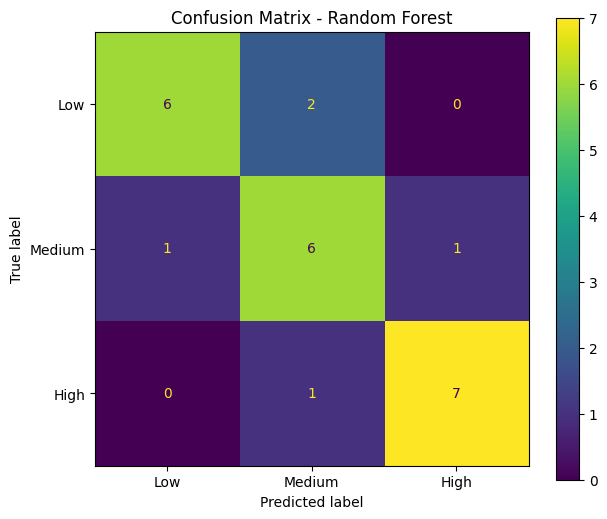

In [116]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["Low", "Medium", "High"]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Low", "Medium", "High"]
)

fig, ax = plt.subplots(figsize=(7, 6))

disp.plot(
    ax=ax,
    values_format="d"
)

plt.title("Confusion Matrix - Random Forest")
plt.show()

In [117]:
evaluation_df = X_test.copy()

evaluation_df["actual_tier"] = y_test
evaluation_df["predicted_tier"] = y_pred
evaluation_df["correct"] = (
    evaluation_df["actual_tier"] ==
    evaluation_df["predicted_tier"]
)
evaluation_df.head(10)

,completion_rate,dropout_rate,avg_score_improvement,avg_quiz_score,avg_watch_time,assignment_submission_rate,forum_activity_rate,avg_feedback_score,feedback_response_rate,actual_tier,predicted_tier,correct
53,0.677122,0.319863,26.873497,75.978810,0.805725,0.786797,0.252786,4.323016,0.757419,Medium,High,False
19,0.575227,0.405341,26.212015,75.525744,0.742808,0.768252,0.211915,4.051842,0.698611,Low,Medium,False
61,0.611583,0.387752,27.203563,79.459434,0.803709,0.762371,0.239603,4.307573,0.746051,Medium,Medium,True
114,0.554042,0.456556,24.361465,77.106179,0.741497,0.769455,0.232349,4.271560,0.646785,Low,Low,True
89,0.680189,0.318909,28.648057,81.701741,0.787011,0.725400,0.281655,4.337380,0.781245,High,High,True
42,0.658435,0.354259,27.841544,80.810344,0.780488,0.717702,0.273402,4.349731,0.741951,Medium,Medium,True
116,0.691715,0.312481,28.430884,80.981607,0.793272,0.814243,0.265179,4.305839,0.713759,High,High,True
41,0.596150,0.406230,27.442320,77.065812,0.777690,0.694311,0.231024,4.113551,0.744287,Medium,Medium,True
48,0.638230,0.352308,29.072296,80.224617,0.807675,0.777514,0.279104,4.223001,0.792893,High,High,True
112,0.356493,0.626740,20.891772,71.264197,0.679547,0.713931,0.207455,3.888738,0.609026,Low,Low,True


### 6.2 Cross-Validation

Because only 120 instructor-level observations are available, performance on a single 24-observation test set may be sensitive to individual observations.

Five-fold stratified cross-validation is therefore used as an additional robustness check. The dataset is divided into five folds while maintaining the class proportions, and the model is trained and evaluated repeatedly using different folds as the validation set.

The mean and standard deviation of the cross-validation F1-score are reported to show both average performance and variation across folds.

In [118]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_f1_scores = cross_val_score(
    rf_model,
    X,
    y,
    cv=cv,
    scoring="f1_macro"
)

print("Cross-validation Macro F1 scores:")
print(cv_f1_scores)

print(
    f"\nMean CV Macro F1: "
    f"{cv_f1_scores.mean():.4f}"
)

print(
    f"Std CV Macro F1: "
    f"{cv_f1_scores.std():.4f}"
)

Cross-validation Macro F1 scores:
[0.91650327 0.83809524 0.91650327 0.78711485 0.95816993]

Mean CV Macro F1: 0.8833
Std CV Macro F1: 0.0618


In [119]:
from sklearn.dummy import DummyClassifier

dummy_model = DummyClassifier(
    strategy="most_frequent"
)
dummy_model.fit(X_train, y_train)
dummy_pred = dummy_model.predict(X_test)
dummy_accuracy = accuracy_score(
    y_test,
    dummy_pred
)
dummy_f1 = f1_score(
    y_test,
    dummy_pred,
    average="macro"
)
print(f"Baseline Accuracy: {dummy_accuracy:.4f}")
print(f"Baseline Macro F1: {dummy_f1:.4f}")

Baseline Accuracy: 0.3333
Baseline Macro F1: 0.1667


In [120]:
performance_summary = pd.DataFrame({
    "Metric": [
        "Test Accuracy",
        "Test Macro F1",
        "Test Balanced Accuracy",
        "Mean CV Macro F1",
        "Std CV Macro F1",
        "Baseline Accuracy",
        "Baseline Macro F1"
    ],
    "Score": [
        accuracy,
        macro_f1,
        balanced_acc,
        cv_f1_scores.mean(),
        cv_f1_scores.std(),
        dummy_accuracy,
        dummy_f1
    ]
})
performance_summary

,Metric,Score
0,Test Accuracy,0.791667
1,Test Macro F1,0.793627
2,Test Balanced Accuracy,0.791667
3,Mean CV Macro F1,0.883277
4,Std CV Macro F1,0.061815
5,Baseline Accuracy,0.333333
6,Baseline Macro F1,0.166667


In [121]:
accuracy_score(y_test, y_pred)

0.7916666666666666

In [122]:
f1_score(y_test, y_pred, average="macro")

0.7936274509803921

In [123]:
balanced_accuracy_score(y_test, y_pred)

0.7916666666666666

### 6.3 Feature Importance

Feature importance is examined to understand which instructor-level metrics contribute most to the Random Forest's classification decisions.

Two approaches are considered:

1. **Random Forest impurity-based importance**, which measures the contribution of each feature to the reduction in impurity across the decision trees.

2. **Permutation importance**, which measures how much model performance decreases when the values of a feature are randomly shuffled.

Permutation importance is particularly useful as a complementary analysis because it evaluates the effect of disrupting the relationship between each feature and the model's predictions.

Feature importance should be interpreted as model association rather than causal influence. In addition, because the effectiveness tiers were constructed from these same metrics, high importance indicates that a feature contributes strongly to reproducing the defined scoring framework rather than proving that the feature independently causes instructor effectiveness.

In [124]:
feature_importance = pd.DataFrame({
    "feature": X.columns,
    "importance": rf_model.feature_importances_
})
feature_importance = feature_importance.sort_values(
    "importance",
    ascending=False
)
feature_importance

,feature,importance
0,completion_rate,0.297055
1,dropout_rate,0.273958
8,feedback_response_rate,0.139829
2,avg_score_improvement,0.075636
3,avg_quiz_score,0.066941
7,avg_feedback_score,0.064773
4,avg_watch_time,0.037005
5,assignment_submission_rate,0.022943
6,forum_activity_rate,0.021859


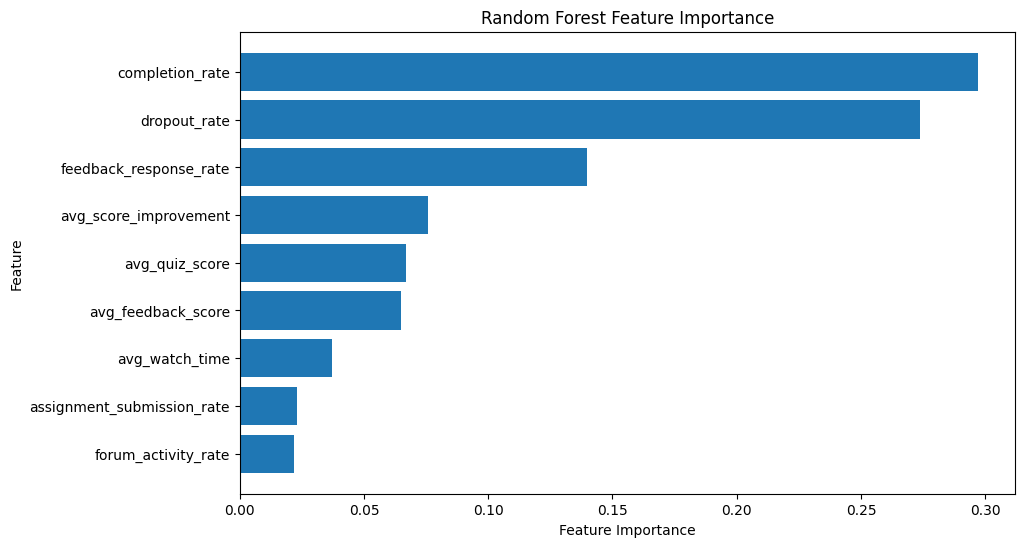

In [125]:
plt.figure(figsize=(10, 6))
plt.barh(
    feature_importance["feature"],
    feature_importance["importance"]
)
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importance")
plt.gca().invert_yaxis()
plt.show()

In [126]:
from sklearn.inspection import permutation_importance

perm_result = permutation_importance(
    rf_model,
    X_test,
    y_test,
    scoring="f1_macro",
    n_repeats=30,
    random_state=42
)

In [127]:
permutation_importance_df = pd.DataFrame({
    "feature": X_test.columns,
    "importance_mean": perm_result.importances_mean,
    "importance_std": perm_result.importances_std
})
permutation_importance_df = permutation_importance_df.sort_values(
    "importance_mean",
    ascending=False
)
permutation_importance_df

,feature,importance_mean,importance_std
1,dropout_rate,0.055814,0.052180
8,feedback_response_rate,0.055741,0.032552
0,completion_rate,0.026365,0.064507
2,avg_score_improvement,0.008824,0.017647
7,avg_feedback_score,-0.001189,0.023039
5,assignment_submission_rate,-0.005211,0.034345
4,avg_watch_time,-0.008598,0.032334
6,forum_activity_rate,-0.009804,0.016258
3,avg_quiz_score,-0.019081,0.021658


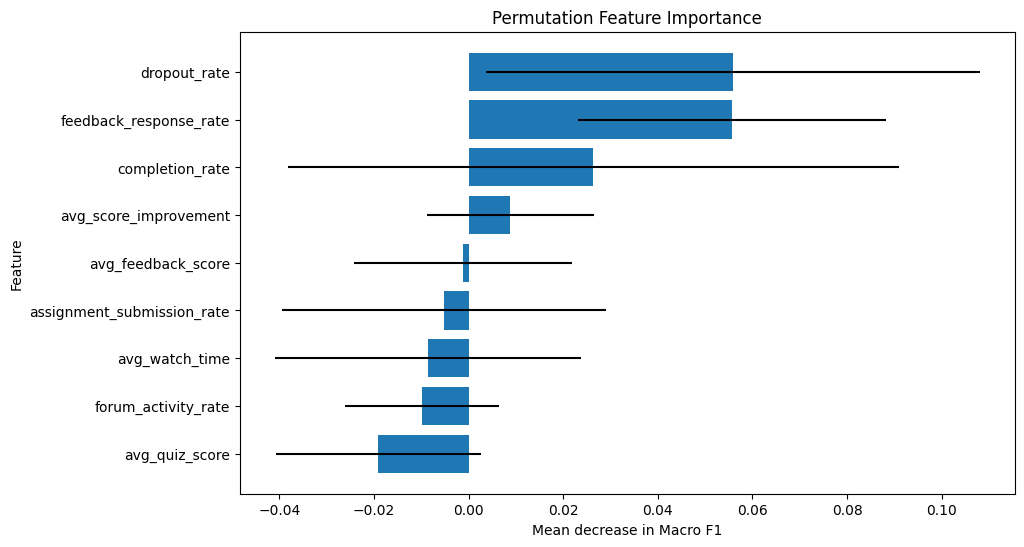

In [128]:
plt.figure(figsize=(10, 6))
plt.barh(
    permutation_importance_df["feature"],
    permutation_importance_df["importance_mean"],
    xerr=permutation_importance_df["importance_std"]
)
plt.xlabel("Mean decrease in Macro F1")
plt.ylabel("Feature")
plt.title("Permutation Feature Importance")
plt.gca().invert_yaxis()
plt.show()

### 6.4 Feature Relationships

The relationships among the instructor-level metrics are examined to identify potential correlations between predictors.

Strongly correlated features may contain overlapping information, which can affect the interpretation of model-based feature importance.

In [129]:
correlation_matrix = X.corr()
correlation_matrix.round(2)

,completion_rate,dropout_rate,avg_score_improvement,avg_quiz_score,avg_watch_time,assignment_submission_rate,forum_activity_rate,avg_feedback_score,feedback_response_rate
completion_rate,1.00,-0.99,0.89,0.85,0.73,0.72,0.75,0.86,0.82
dropout_rate,-0.99,1.00,-0.89,-0.84,-0.72,-0.70,-0.76,-0.85,-0.82
avg_score_improvement,0.89,-0.89,1.00,0.73,0.64,0.69,0.67,0.75,0.79
avg_quiz_score,0.85,-0.84,0.73,1.00,0.70,0.62,0.69,0.76,0.71
avg_watch_time,0.73,-0.72,0.64,0.70,1.00,0.53,0.61,0.64,0.64
assignment_submission_rate,0.72,-0.70,0.69,0.62,0.53,1.00,0.43,0.60,0.59
forum_activity_rate,0.75,-0.76,0.67,0.69,0.61,0.43,1.00,0.66,0.62
avg_feedback_score,0.86,-0.85,0.75,0.76,0.64,0.60,0.66,1.00,0.75
feedback_response_rate,0.82,-0.82,0.79,0.71,0.64,0.59,0.62,0.75,1.00


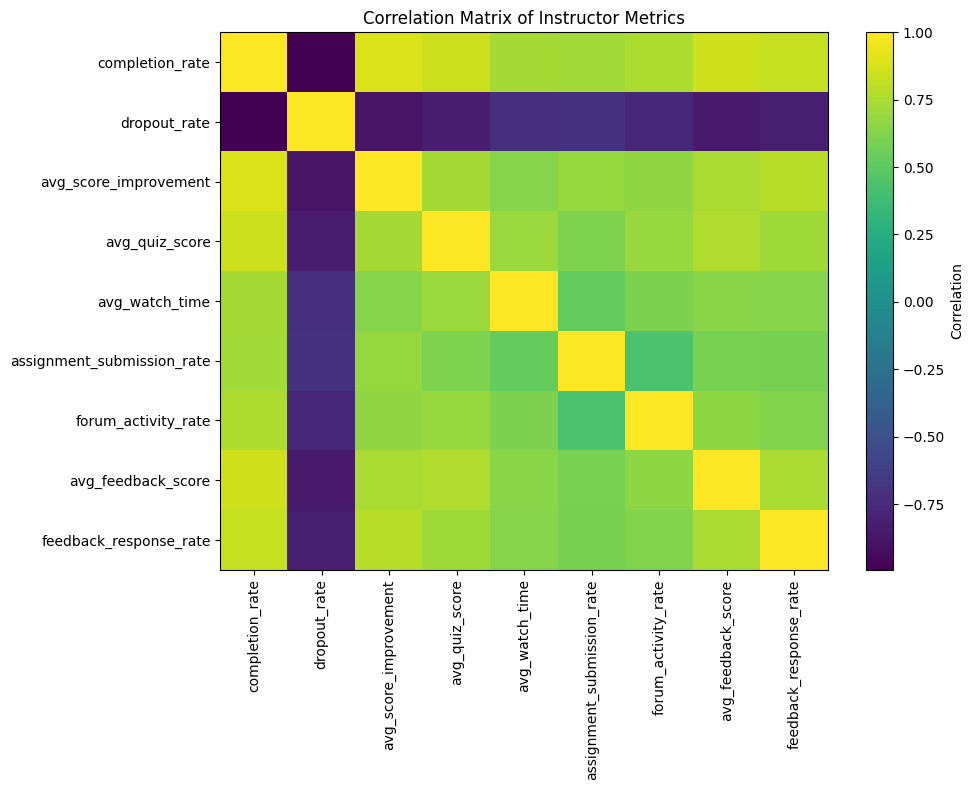

In [130]:
plt.figure(figsize=(10, 8))
plt.imshow(
    correlation_matrix,
    aspect="auto"
)
plt.colorbar(label="Correlation")
plt.xticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns,
    rotation=90
)
plt.yticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns
)
plt.title("Correlation Matrix of Instructor Metrics")
plt.tight_layout()
plt.show()

### 6.5 Correlation and Feature Redundancy Check

The correlation analysis shows several strong relationships among the instructor-level metrics. In particular, `completion_rate` and `dropout_rate` have a correlation of approximately -0.99, indicating that they contain highly overlapping information.

Because highly correlated predictors can affect feature-importance interpretation, a small robustness experiment is performed by removing `dropout_rate` while retaining `completion_rate`.

The purpose of this experiment is not to replace the primary model automatically, but to determine whether model performance and feature interpretation are highly dependent on this redundant pair of variables.

In [131]:
reduced_features = [
    feature for feature in model_features
    if feature != "dropout_rate"
]

X_reduced = instructor_df[reduced_features].copy()

In [132]:
X_train_red, X_test_red, y_train_red, y_test_red = train_test_split(
    X_reduced,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [133]:
rf_reduced = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    max_depth=5
)

rf_reduced.fit(X_train_red, y_train_red)

,n_estimators,200
,criterion,'gini'
,max_depth,5
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [134]:
cv_scores_reduced = cross_val_score(
    rf_reduced,
    X_reduced,
    y,
    cv=cv,
    scoring="f1_macro"
)

print("Reduced Model CV Macro F1 scores:")
print(cv_scores_reduced)

print(
    f"\nMean Reduced Model CV Macro F1: "
    f"{cv_scores_reduced.mean():.4f}"
)

print(
    f"Std Reduced Model CV Macro F1: "
    f"{cv_scores_reduced.std():.4f}"
)

Reduced Model CV Macro F1 scores:
[0.91650327 0.83809524 0.91650327 0.79084967 1.        ]

Mean Reduced Model CV Macro F1: 0.8924
Std Reduced Model CV Macro F1: 0.0721


### 6.6 Robustness Check: Removing Highly Correlated Outcome Metrics

Completion rate and dropout rate exhibit an extremely strong negative correlation. To further examine the dependence of the classifier on these overlapping outcome measures, an additional robustness experiment is performed by removing both variables.

This experiment is used only to understand how much predictive information is contained in the remaining engagement, performance, and feedback metrics. It does not automatically change the primary effectiveness scoring framework.

In [135]:
features_without_outcomes = [
    feature for feature in model_features
    if feature not in ["completion_rate", "dropout_rate"]
]

X_without_outcomes = instructor_df[features_without_outcomes].copy()

In [136]:
X_train_wo, X_test_wo, y_train_wo, y_test_wo = train_test_split(
    X_without_outcomes,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [137]:
rf_without_outcomes = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    max_depth=5
)

rf_without_outcomes.fit(
    X_train_wo,
    y_train_wo
)

,n_estimators,200
,criterion,'gini'
,max_depth,5
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [138]:
cv_scores_without_outcomes = cross_val_score(
    rf_without_outcomes,
    X_without_outcomes,
    y,
    cv=cv,
    scoring="f1_macro"
)

print("CV Macro F1 scores:")
print(cv_scores_without_outcomes)

print(
    f"\nMean CV Macro F1: "
    f"{cv_scores_without_outcomes.mean():.4f}"
)

print(
    f"Std CV Macro F1: "
    f"{cv_scores_without_outcomes.std():.4f}"
)

CV Macro F1 scores:
[0.95816993 0.83664021 0.83703704 0.83333333 0.91650327]

Mean CV Macro F1: 0.8763
Std CV Macro F1: 0.0515


In [139]:
robustness_summary = pd.DataFrame({
    "Model": [
        "Original - 9 Features",
        "Without Dropout Rate",
        "Without Completion & Dropout"
    ],
    "Number of Features": [
        9,
        8,
        7
    ],
    "Mean CV Macro F1": [
        0.8833,
        0.8924,
        0.8763
    ],
    "Std CV Macro F1": [
        0.0618,
        0.0721,
        0.0515
    ]
})

robustness_summary

,Model,Number of Features,Mean CV Macro F1,Std CV Macro F1
0,Original - 9 Features,9,0.8833,0.0618
1,Without Dropout Rate,8,0.8924,0.0721
2,Without Completion & Dropout,7,0.8763,0.0515


### Robustness Check Interpretation

The robustness analysis shows that completion rate and dropout rate contain highly overlapping information, as indicated by their strong negative correlation. Removing dropout rate alone resulted in a small increase in mean cross-validated Macro F1, while removing both completion and dropout resulted in a decrease in performance.

Because the differences are relatively small and the dataset contains only 120 instructors, the original nine-feature model is retained as the primary model. The reduced models are treated as sensitivity analyses rather than replacements for the primary scoring framework.

## 7. Final Instructor Effectiveness Profile

The final instructor-level profile combines the three dimension scores with the overall effectiveness score and effectiveness tier.

This table provides an interpretable view of instructor performance by showing not only the overall effectiveness level, but also the underlying Outcome, Engagement, and Feedback dimensions.

The resulting profile will be used to identify areas of strength and potential improvement and to develop actionable recommendations for instructors and the EdTech platform.

In [143]:
final_instructor_profile = instructor_scores[
    [
        "instructor_id",
        "outcome_score",
        "engagement_score",
        "feedback_score",
        "effectiveness_score",
        "effectiveness_tier"
    ]
].copy()

In [144]:
score_columns = [
    "outcome_score",
    "engagement_score",
    "feedback_score",
    "effectiveness_score"
]

final_instructor_profile[score_columns] = (
    final_instructor_profile[score_columns]
    .round(3)
)

final_instructor_profile.head(10)

,instructor_id,outcome_score,engagement_score,feedback_score,effectiveness_score,effectiveness_tier
0,I_001,0.469,0.477,0.441,0.462,Medium
1,I_002,0.688,0.691,0.658,0.679,High
2,I_003,0.695,0.681,0.762,0.713,High
3,I_004,0.333,0.519,0.407,0.420,Low
4,I_005,0.848,0.865,0.580,0.765,High
5,I_006,0.225,0.312,0.261,0.266,Low
6,I_007,0.672,0.668,0.575,0.638,High
7,I_008,0.568,0.588,0.652,0.603,High
8,I_009,0.477,0.490,0.620,0.529,Medium
9,I_010,0.995,0.917,0.951,0.954,High


In [145]:
tier_dimension_summary = (
    final_instructor_profile
    .groupby("effectiveness_tier")[
        [
            "outcome_score",
            "engagement_score",
            "feedback_score",
            "effectiveness_score"
        ]
    ]
    .mean()
    .round(3)
)

tier_dimension_summary

C:\Users\R y z e n\AppData\Local\Temp\ipykernel_9256\2008823625.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("effectiveness_tier")[


,outcome_score,engagement_score,feedback_score,effectiveness_score
effectiveness_tier,,,,
Low,0.306,0.388,0.306,0.333
Medium,0.502,0.521,0.489,0.504
High,0.698,0.675,0.705,0.692


## 8. Interpret the Results

The analysis suggests that instructor effectiveness is influenced by multiple aspects of the learner experience rather than by a single metric.

The Random Forest feature-importance analysis identified `completion_rate`, `dropout_rate`, and `feedback_response_rate` as the most influential features. Permutation importance also identified these three variables among the most important predictors.

However, these results should be interpreted as model associations rather than causal relationships. The effectiveness tiers were constructed using the same underlying metrics provided to the model, so the model is primarily learning to reproduce the defined scoring framework rather than independently proving what causes instructor effectiveness.

The correlation analysis also showed substantial relationships between several metrics. In particular, `completion_rate` and `dropout_rate` had a correlation of approximately -0.99, indicating that they contain highly overlapping information.

Therefore, the results are most useful for understanding patterns within the constructed effectiveness framework and identifying areas that may require further investigation.

### Key Features Influencing Instructor Effectiveness

The Random Forest impurity-based feature importance ranked the features as follows:

1. `completion_rate` – 0.297
2. `dropout_rate` – 0.274
3. `feedback_response_rate` – 0.140
4. `avg_score_improvement` – 0.076
5. `avg_quiz_score` – 0.067
6. `avg_feedback_score` – 0.065
7. `avg_watch_time` – 0.037
8. `assignment_submission_rate` – 0.023
9. `forum_activity_rate` – 0.022

Permutation importance provided a somewhat different ranking, but `dropout_rate`, `feedback_response_rate`, and `completion_rate` remained the most influential group.

This suggests that learner completion, learner attrition, and feedback participation contain substantial information for distinguishing the effectiveness tiers defined in this analysis.

The strong negative correlation between completion rate and dropout rate should be considered when interpreting their individual importance. These two metrics represent related aspects of learner retention and contain highly overlapping information.

The analysis therefore indicates that learner outcome and retention measures are particularly important within the constructed effectiveness framework, rather than proving that these variables independently cause instructor effectiveness.

### Results in Simple Terms

In simple terms, instructors who are associated with better learner completion and lower learner dropout tend to receive stronger effectiveness scores in this framework.

Learner feedback participation also appears to provide useful information. This means that understanding whether learners complete courses, remain engaged with the learning journey, and provide feedback can help the platform understand differences between instructors.

However, these metrics should not be interpreted independently. For example, completion rate and dropout rate are almost mirror measures in this dataset. In addition, learner performance and engagement may be affected by factors other than the instructor.

Therefore, the effectiveness score should be viewed as a structured indicator that summarizes available data, rather than a definitive measure of teaching quality.

### Potential Use in an EdTech Product

The effectiveness framework could be used as a decision-support tool rather than as an automatic ranking system.

Potential applications include:

- Identifying instructors who may benefit from additional support or training.
- Identifying the weakest dimension for an instructor, such as learner outcomes, engagement, or feedback.
- Helping academic managers investigate unusually low completion or high dropout patterns.
- Monitoring changes in instructor effectiveness across batches over time.
- Identifying instructors whose learner outcomes and engagement patterns could provide useful examples for internal best-practice sharing.
- Providing instructors with a data-driven summary of areas that may require attention.

For example, an instructor with a relatively low engagement score but stronger outcome and feedback scores could receive targeted support focused on learner participation rather than general teaching training.

The system should therefore be used to generate insights and guide further investigation, rather than automatically making high-impact decisions about instructors.

## 9. Mandatory Analysis Questions


### 9.1 Which features most influenced instructor effectiveness, and why?

The features that most influenced the Random Forest's classification were `completion_rate`, `dropout_rate`, and `feedback_response_rate`.

`completion_rate` had the highest impurity-based feature importance (0.297), while `dropout_rate` was second (0.274). `feedback_response_rate` was third (0.140). Permutation importance also placed these three variables among the most influential features.

These features are intuitively relevant to the effectiveness framework:

- `completion_rate` reflects how many learners successfully complete the course.
- `dropout_rate` reflects learner attrition.
- `feedback_response_rate` indicates how actively learners participate in providing feedback.

However, completion rate and dropout rate are extremely strongly correlated in this dataset (approximately -0.99). Therefore, their importance should not be interpreted as two completely independent effects.

The robustness analysis supports this interpretation. Removing `dropout_rate` alone produced a similar cross-validated Macro F1 (0.8924 compared with 0.8833 for the original model), while removing both `completion_rate` and `dropout_rate` reduced the mean cross-validated Macro F1 to 0.8763.

Overall, the results suggest that learner outcome and retention information is particularly useful for distinguishing the effectiveness tiers created by this scoring framework.

### 9.2 Which variables could be misleading or confounded?

Several variables could be influenced by factors other than instructor effectiveness.

First, `completion_rate` and `dropout_rate` are highly correlated, with a correlation of approximately -0.99. This means that they contain largely overlapping information and should not be interpreted as completely independent signals.

Second, learner performance metrics such as `avg_quiz_score` and `avg_score_improvement` may depend on factors such as course difficulty, assessment difficulty, learner background, or prior knowledge, and not only on instructor quality.

Engagement metrics such as `avg_watch_time`, `assignment_submission_rate`, and `forum_activity_rate` may also be affected by learner motivation, course design, workload, or the way the course is delivered.

Feedback-related variables may also be subject to response bias. Learners who choose to submit feedback may not represent all learners, meaning that `feedback_response_rate` and `avg_feedback_score` may not fully represent the opinions of the entire learner population.

Another important limitation is that instructors may teach different courses or batches with different learner populations. Without additional information about course difficulty, learner characteristics, class size, or instructor assignment, differences between instructors cannot necessarily be attributed entirely to instructor effectiveness.

Therefore, the variables should be treated as signals associated with effectiveness rather than direct measures of instructor quality.

### 9.3 How could this model fail in real-world usage?

The model could fail or produce misleading results in several situations.

#### 1. Changes in learner population

The model was developed using a specific dataset. If future learners have substantially different backgrounds, motivation levels, or learning behavior, the relationships learned by the model may no longer hold.

#### 2. Course differences

Instructors may teach courses with different levels of difficulty or different learner expectations. A lower completion rate may therefore reflect a difficult course rather than poor instruction.

#### 3. Small sample sizes

An instructor with only a small number of batches may receive a score that is strongly affected by a single unusual batch. This makes the estimate less reliable.

#### 4. Changes over time

Instructor performance, course structure, technology, and learner behavior can change over time. A model trained on historical data may become less representative of current conditions.

#### 5. Feedback bias

Learner feedback may not represent all learners. Highly satisfied or dissatisfied learners may be more likely to provide feedback.

#### 6. Target construction dependency

The effectiveness tiers were created from the same metrics that are later used as model inputs. Therefore, strong model performance mainly demonstrates that the classifier can reproduce the defined scoring framework. It does not independently validate the framework against an external measure of teaching quality.

#### 7. Over-reliance on the score

A single numerical score can hide important context. An instructor may have a lower score because of learner or course-related factors outside the instructor's control.

For these reasons, the model should be periodically monitored and validated using new data before being used in a real-world decision-making system.

### 9.4 What additional data would you want to improve this analysis?

Additional data could make the effectiveness estimate more reliable and help separate instructor effects from other factors.

#### Learner and batch information
- Number of learners in each batch
- Learner prior knowledge or pre-course assessment level
- Learner demographic or experience information where appropriate and ethically justified
- Attendance and session participation

#### Course information
- Course difficulty level
- Course category and subject
- Course duration
- Assessment difficulty
- Changes in course content or curriculum between batches

#### Instructor information
- Instructor experience
- Years of teaching experience
- Instructor training or certifications
- Historical performance across courses and batches
- Instructor workload and number of concurrent batches

#### More detailed learning outcomes
- Pre- and post-assessment distributions rather than only averages
- Assessment pass rates
- Assignment quality
- Long-term learner retention
- Learning outcomes measured after course completion

#### Better feedback information
- Number of feedback responses
- Distribution of feedback ratings
- Qualitative feedback from learners
- Feedback collected at multiple points during the course

These additional variables would help control for factors that may influence learner outcomes independently of the instructor and would allow a more reliable assessment of instructor effectiveness.

### 9.5 Should this model be used for instructor performance evaluation? Why or why not?

The model should not be used as the sole basis for evaluating instructor performance.

The model provides a useful quantitative summary of learner outcomes, engagement, and feedback, but these measures can be affected by factors outside an instructor's control. The analysis also shows strong correlations between several variables, and the effectiveness tiers themselves are constructed from the available metrics rather than from an independently measured ground-truth definition of teaching quality.

Using the model as the sole basis for performance evaluation could therefore result in unfair conclusions, particularly when instructors teach different courses, different learner populations, or different batch sizes.

A more appropriate use would be as a decision-support and diagnostic tool. For example, the model could identify instructors or dimensions that deserve further investigation, after which managers could consider additional evidence such as learner feedback, course difficulty, instructor experience, classroom observations, and longitudinal performance.

The model should also be monitored and periodically revalidated as new data becomes available.

Therefore, the model is suitable for identifying patterns and supporting instructor development, but it should not automatically determine promotions, penalties, compensation, or other high-impact decisions about instructors.

## 10. Conclusion

This analysis developed an instructor effectiveness framework using learner outcomes, engagement, and feedback metrics.

Batch-level data was first aggregated to the instructor level. The available metrics were normalized and grouped into three dimensions: Outcome, Engagement, and Feedback. These dimensions were combined using equal weights to produce an overall Instructor Effectiveness Score, which was then divided into Low, Medium, and High effectiveness tiers.

A Random Forest classifier was trained to reproduce these tiers. The model achieved a test accuracy of 79.17% and a test Macro F1-score of 79.36%. Five-fold stratified cross-validation produced a mean Macro F1 of 88.33% with a standard deviation of 6.18%.

Feature analysis showed that completion rate, dropout rate, and feedback response rate were the most influential features. Correlation analysis also revealed substantial relationships between several metrics, particularly the very strong negative correlation between completion rate and dropout rate. Robustness checks showed that removing one of these highly correlated variables had little effect on model performance, while removing both reduced performance.

The analysis demonstrates how available EdTech data can be transformed into an interpretable instructor effectiveness framework. However, the resulting score should be treated as an analytical indicator rather than an absolute measure of teaching quality.

In a real EdTech environment, the framework would be most appropriate as a decision-support tool for identifying patterns, supporting instructor development, and highlighting areas for further investigation. Additional learner, course, batch, and instructor information would be required before making high-impact decisions based on the model.